## Семинар 1. Обнаружение кораблей на SAR-изображениях (SARscope + YOLOv8)
Строим полный конвейер: подготовка данных, разведочный анализ, обучение детектора, подсчёт метрик и разбор ошибок.

## Введение

Датасет SARscope был разработан для поддержки исследований и разработок в области обнаружения кораблей и их сегментации на основе РСА. Объединив сильные стороны двух известных датасетов — HRSID и OPEN-SSDD, SARscope предоставляет разнообразный и обогащенный набор данных, состоящий из 6 735 изображений РСА и 17 708 размеченных экземпляров кораблей (по описанию авторов; ниже мы пересчитаем объекты сами и получим другое число). Эти изображения, измененные до размера 640×640 пикселей для вычислительной эффективности, включают VV и VH поляризации и распределены по подмножествам для обучения (70%), валидации (20%) и тестирования (10%). Аннотации предоставлены в формате COCO-MMDetection для обеспечения совместимости с современными фреймворками обнаружения объектов.

## Постановка задачи

Цель семинара — построить конвейер глубокого обучения для автоматического **обнаружения** кораблей на изображениях РСА (разметка SARscope позволяет решать и сегментацию экземпляров, но на семинаре мы ограничимся детекцией). Задача включает работу со специфичными для предметной области проблемами: спекл-шум, разные масштабы объектов, низкое отношение сигнал/шум и разный вид объектов в разных поляризациях.

Для этого датасет нужно предварительно обработать и привести к формату, совместимому с детекторами семейства YOLO: реструктурировать директории с изображениями и сконвертировать аннотации из формата COCO в формат YOLO. Конечная цель — обучить и оценить модель обнаружения, которая хорошо обобщается на разнообразных и сложных примерах из SARscope.

## Настройка окружения

Этот раздел инициализирует окружение и подготавливает иерархию папок, необходимую для организации датасета в формате, совместимом с YOLO.

### Установка пакетов

Если необходимо, установите следующие пакеты:
- **`numpy`** и **`pandas`**: численная и табличная обработка данных.
- **`matplotlib`**: визуализация данных.
- **`pylabel`**: лёгкая библиотека для конвертации форматов аннотаций, например из COCO в YOLO.
- **`ultralytics`**: официальная библиотека для моделей семейства YOLO, включающая утилиты для обучения и оценки.
- **`pillow`**: работа с изображениями.

> **Если у вас нет GPU.** Ноутбук работает в Google Colab и Kaggle (GPU T4). Одно обучение на 50 эпох там занимает порядка часа, а в ноутбуке их три. Для экономии времени уменьшите `epochs` или используйте выложенные веса.

In [1]:
%pip install -q numpy pandas matplotlib pillow pylabel ultralytics

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import glob 
import json 
import shutil
import yaml
from PIL import Image
import torch
from ultralytics import YOLO
from pylabel import importer
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

### Скачайте датасет по ссылке

[Ссылка на датасет](https://mega.nz/file/2NBjEQDR#7BRjRzuIhZBl-Qn4ctMw0YcSdTEdLFsk0LWwlRcGuR4)

In [7]:
# Укажите путь до папки с данными после скачивания и распаковки.
# Внутри должны быть папки train / valid / test.
# Примеры: r"C:\datasets\SARscope\data" (Windows), "/content/SARscope/data" (Colab),
# "/kaggle/working/SARscope/data" (Kaggle: /kaggle/input доступна только на чтение -- скопируйте данные в /kaggle/working)
data_path = os.path.join("content", "SARscope", "data")

### Конвертация формата аннотаций (COCO -> YOLO)

Функция `convert_coco2Yolo` использует **`pylabel`** для:
1. Загрузки файла аннотаций в формате COCO (.json) из исходной директории.
2. Парсинга датасета и связывания его с папкой изображений.
3. Экспорта аннотаций в формат YOLOv5 с сохранением в указанную директорию `dst_path`.

> **Про номера классов.** pylabel по умолчанию переносит `category_id` из COCO как есть. В SARscope единственная категория `ship` имеет `id = 1`, поэтому в YOLO-разметке корабли получат класс `1`, а класс `0` останется пустым. Обучению это не мешает (ниже это будет видно как `nc: 2` и класс `unused_0`), но аккуратнее переиндексировать категории с нуля: `dataset.export.ExportToYoloV5(dst_path, cat_id_index=0)`. Сейчас оставлено поведение по умолчанию, чтобы результаты совпадали с теми, что разбирались на занятии.

In [3]:
def convert_coco2Yolo(source_path):
    dst_path = os.path.join(source_path, "labels")
    os.makedirs(dst_path, exist_ok=True)
    json_file = glob.glob(os.path.join(source_path, "*.json"))
    dataset = importer.ImportCoco(json_file[0], path_to_images=source_path, name="SARscope")
    dataset.export.ExportToYoloV5(dst_path)

def move_images(source_path):
    images_path = os.path.join(source_path, "images")
    os.makedirs(images_path, exist_ok=True)
    images = glob.glob(os.path.join(source_path, "*.jpg"))
    for im in images:
        dst_path = os.path.join(images_path, os.path.basename(im))
        shutil.move(im, dst_path)

### Конвертация аннотаций для каждого разбиения (сплита)

Этот блок конвертирует файлы аннотаций для сплитов из формата COCO в формат YOLOv5, сохраняя результат в директории **`labels/`** внутри каждого сплита. Функция `move_images` перемещает все изображения в директорию **`images/`**.

Такая структура (папки **`images/`** и **`labels/`**) требуется для обучения YOLO. Если конвертация уже выполнялась, сплит пропускается — ячейку можно безопасно запускать повторно.

In [ ]:
splits = ["train", "valid", "test"]

for spl in splits:
    source_path = os.path.join(data_path, spl)
    if glob.glob(os.path.join(source_path, "labels", "*.txt")):
        print(f"{spl}: разметка уже сконвертирована, пропускаем")
        continue
    convert_coco2Yolo(source_path)
    move_images(source_path)

## Разведочный анализ данных (EDA)

В этом блоке посмотрим на данные, с которыми нам предстоит работать, а именно:
1. Посмотрим на несколько случайных примеров с разметкой
2. Посмотрим на распределение количества кораблей на одном изображении
3. Посмотрим на плотность распределения кораблей по изображению
4. Посмотрим на распределение размеров bbox'ов

> Bounding box (bbox) в формате YOLO выглядит как: `class x_center y_center width height`, где все координаты нормированы на размер изображения.


In [4]:
# Закрепляем сид для воспроизводимости результатов
random.seed(2026)
np.random.seed(2026)

In [5]:
def visualize_images_with_annotations(base_path, num_samples=5):
    # Получаем список всех изображений
    image_files = glob.glob(os.path.join(base_path, "*", "images", "*.jpg"))
    
    # Выбираем случайные изображения
    selected_images = random.sample(image_files, num_samples)
    
    # Подготавливаем оси
    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 4*num_samples), dpi=100)
    if num_samples == 1:
        axes = axes.reshape(1, -1)
    
    for idx, img_path in enumerate(selected_images):
        # Загружаем изображение и аннотацию
        img = Image.open(img_path)
        img_array = np.array(img)
        img_name = os.path.basename(img_path).split("_")[0]
        label_path = str(img_path).replace('.jpg', '.txt').replace("images", "labels")
        annotations = []  # если файла разметки нет -- на изображении нет кораблей
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        cls, xc, yc, w, h = map(float, parts)
                        # Конвертируем из нормализованных YOLO координат в пиксели
                        x1 = (xc - w/2) * img.width
                        y1 = (yc - h/2) * img.height
                        x2 = (xc + w/2) * img.width
                        y2 = (yc + h/2) * img.height
                        annotations.append((x1, y1, x2, y2))
        
        # Отрисовываем
        axes[idx, 0].imshow(img_array, cmap='gray')
        axes[idx, 0].axis('off')
        axes[idx, 0].set_title(f'Image: {img_name}\nShips: {len(annotations)}', fontsize=10)
        axes[idx, 1].imshow(img_array, cmap='gray')
        axes[idx, 1].axis('off')
        for (x1, y1, x2, y2) in annotations:
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, 
                                    linewidth=1, edgecolor='lime', facecolor='none')
            axes[idx, 1].add_patch(rect)
        axes[idx, 1].set_title(f'With Annotations\n{len(annotations)} ships are on the image', 
                              fontsize=10, fontweight='bold')
    
    plt.suptitle('SARscope Dataset: Sample Images with Ship Annotations', 
                fontsize=14, fontweight='bold', y=0.995)
    # plt.tight_layout()
    plt.show()


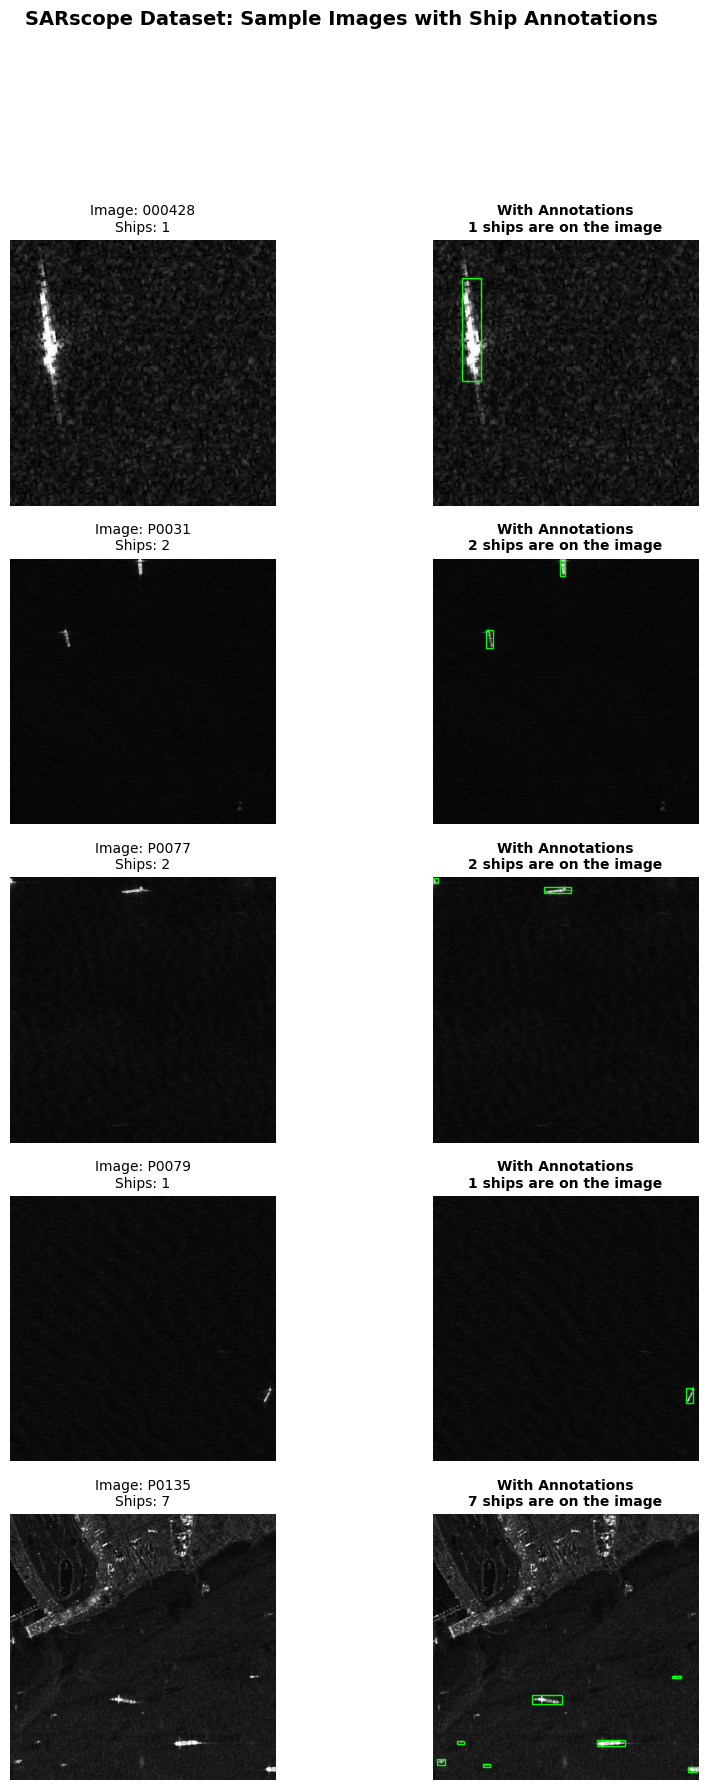

In [8]:
visualize_images_with_annotations(data_path, num_samples=5)

### Зачем смотреть на распределение количества кораблей

- Проверяем, насколько разнообразна выборка: есть ли пустые кадры (без единого корабля) и кадры с большим количеством кораблей одновременно.
- Сильный перекос (например, если значительная доля изображений вообще без объектов) — сигнал задуматься над стратегией сэмплирования при обучении.

In [9]:
def analyze_ship_count_distribution(base_path):
    """
    Анализирует распределение количества кораблей на изображении: помогает
    понять, насколько разнообразна выборка, и не перекошена ли она в сторону
    пустых кадров или кадров с аномально большим числом объектов.
    """
    label_files = glob.glob(os.path.join(base_path, "*", "labels", "*.txt"))
    ship_counts = []
    for label_file in label_files:
        with open(label_file, 'r') as f:
            count = len([line for line in f if line.strip()])
        ship_counts.append(count)
    ship_counts = np.array(ship_counts)

    total_images = len(ship_counts)
    images_without_ships = int((ship_counts == 0).sum())

    # Сводная таблица вместо "простыни" print'ов
    summary = pd.Series({
        "Всего изображений": total_images,
        "Изображений без кораблей": f"{images_without_ships} ({images_without_ships/total_images:.1%})",
        "Всего кораблей": int(ship_counts.sum()),
        "Среднее число кораблей/изображение": round(float(ship_counts.mean()), 2),
        "Медиана": int(np.median(ship_counts)),
        "Максимум на одном изображении": int(ship_counts.max()),
        "Стд. отклонение": round(float(ship_counts.std()), 2),
    }, name="Значение")
    display(summary.to_frame())

    # Группируем в диапазоны -- один бар на каждое уникальное значение
    # нечитаем, когда встречаются изображения с 30-40+ кораблями сразу
    bin_edges = [-0.5, 0.5, 1.5, 2.5, 5.5, 10.5, 20.5, max(int(ship_counts.max()), 21) + 0.5]
    bin_labels = ["0", "1", "2", "3–5", "6–10", "11–20", "21+"]
    binned = pd.cut(ship_counts, bins=bin_edges, labels=bin_labels)
    counts_per_bin = binned.value_counts().reindex(bin_labels)

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(bin_labels, counts_per_bin.values, color="steelblue", alpha=0.85, edgecolor="black")
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, h, f"{int(h)}", ha="center", va="bottom", fontsize=10)
    ax.set_xlabel("Количество кораблей на изображении", fontsize=11, fontweight="bold")
    ax.set_ylabel("Количество изображений", fontsize=11, fontweight="bold")
    ax.set_title("Распределение числа кораблей на изображении (SARscope)", fontsize=13, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    frac_empty = images_without_ships / total_images
    frac_many = (ship_counts > 10).mean()
    print(f"Вывод: {frac_empty:.0%} изображений вообще без кораблей, а {frac_many:.0%} — с более чем "
          f"10 кораблями одновременно. Распределение сильно несимметрично (длинный хвост) — это стоит "
          f"учитывать и при формировании батчей, и при интерпретации средних значений метрик.")

    return ship_counts

,Значение
Всего изображений,6735
Изображений без кораблей,1 (0.0%)
Всего кораблей,19435
Среднее число кораблей/изображение,2.89
Медиана,1
Максимум на одном изображении,163
Стд. отклонение,6.1


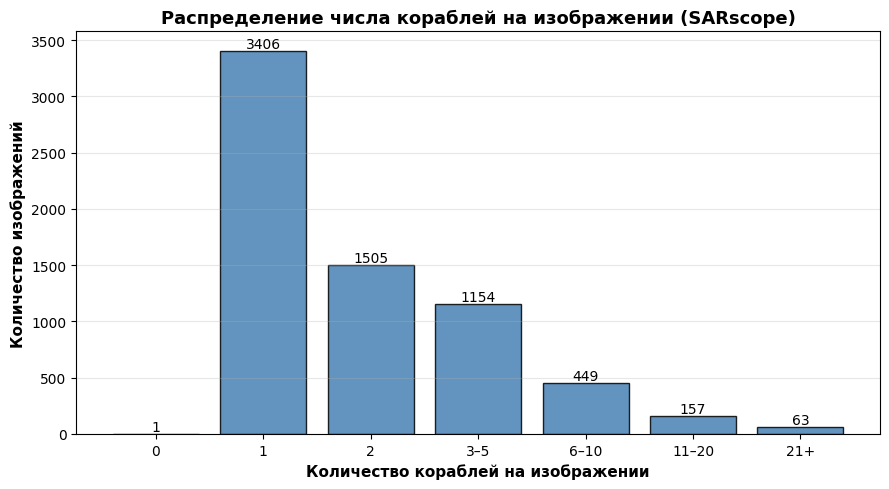

Вывод: 0% изображений вообще без кораблей, а 3% — с более чем 10 кораблями одновременно. Распределение сильно несимметрично (длинный хвост) — это стоит учитывать и при формировании батчей, и при интерпретации средних значений метрик.


In [10]:
ship_counts = analyze_ship_count_distribution(data_path)

- Сверяем число объектов с заявленным в описании датасета: здесь получилось 19 435 рамок против 17 708 в описании. Цифрам из описания датасета не стоит верить без проверки.

### Зачем смотреть на плотность расположения кораблей по кадру

- Если корабли систематически оказываются в одной части кадра (например, у краёв или в центре), это часто артефакт способа съёмки/нарезки данных, а не свойство реального мира
- Такое смещение подсказывает, какие геометрические аугментации безопасны: если модель по факту видела корабли только в центре, агрессивный кроп или сдвиг может создавать нереалистичные примеры
- Проверим это количественно через сетку 3×3 поверх карты плотности — надёжнее, чем оценивать «на глаз» по одной картинке

In [9]:
def create_ship_density_heatmap(base_path, img_size=640, n_bins=40, grid=3):
    """
    Строит карту плотности расположения центров кораблей по кадру и
    количественно проверяет, нет ли систематического смещения объектов
    к краю или к центру изображения.
    """
    label_files = glob.glob(os.path.join(base_path, "*", "labels", "*.txt"))

    centers_x, centers_y = [], []
    for label_file in label_files:
        with open(label_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    _, xc, yc, w, h = map(float, parts)
                    centers_x.append(xc * img_size)
                    centers_y.append(yc * img_size)
    centers_x = np.array(centers_x)
    centers_y = np.array(centers_y)

    # Векторизованная 2D-гистограмма по центрам
    heatmap, _, _ = np.histogram2d(centers_x, centers_y, bins=n_bins,
                                    range=[[0, img_size], [0, img_size]])
    heatmap = heatmap.T  # чтобы строки соответствовали Y, столбцы -- X

    fig, ax = plt.subplots(figsize=(7.5, 7))
    im = ax.imshow(heatmap, cmap="inferno", origin="upper",
                    extent=[0, img_size, img_size, 0])
    plt.colorbar(im, ax=ax, label="Число кораблей в ячейке")
    ax.set_title(f"Плотность расположения кораблей по кадру\n({len(centers_x)} объектов, SARscope)",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("X, px"); ax.set_ylabel("Y, px")

    # Количественная проверка: доля кораблей в ячейках grid x grid сетки
    cell = img_size / grid
    row_idx = np.clip((centers_y // cell).astype(int), 0, grid - 1)
    col_idx = np.clip((centers_x // cell).astype(int), 0, grid - 1)
    grid_counts = np.zeros((grid, grid), dtype=int)
    np.add.at(grid_counts, (row_idx, col_idx), 1)
    total = len(centers_x)
    grid_pct = grid_counts / total * 100

    for i in range(grid):
        for j in range(grid):
            ax.text(j * cell + cell / 2, i * cell + cell / 2, f"{grid_pct[i, j]:.1f}%",
                    color="white", ha="center", va="center", fontsize=12, fontweight="bold",
                    bbox=dict(boxstyle="round", facecolor="black", alpha=0.35, edgecolor="none"))
    for k in range(1, grid):
        ax.axhline(k * cell, color="white", linewidth=0.8, alpha=0.6)
        ax.axvline(k * cell, color="white", linewidth=0.8, alpha=0.6)

    plt.tight_layout()
    plt.show()

    center_pct = grid_pct[grid // 2, grid // 2]
    uniform_pct = 100 / grid ** 2
    if center_pct > uniform_pct * 1.3:
        bias = "заметен сдвиг к центру кадра"
    elif center_pct < uniform_pct * 0.7:
        bias = "заметен сдвиг к краям кадра"
    else:
        bias = "выраженного смещения к центру/краю не видно"
    print(f"Вывод: в центральной ячейке сетки {grid}x{grid} — {center_pct:.1f}% всех кораблей "
          f"(при равномерном распределении ожидалось бы ~{uniform_pct:.1f}%). Похоже, что {bias}.")

    return heatmap

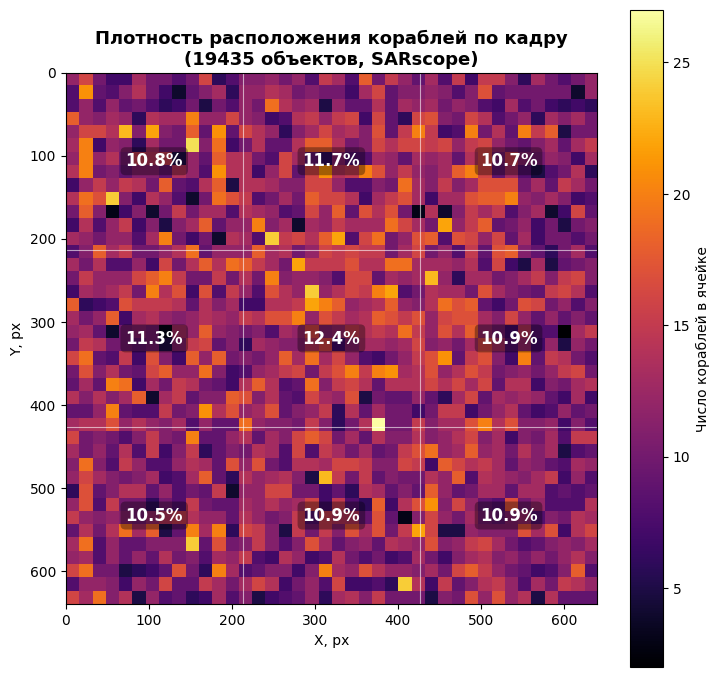

Вывод: в центральной ячейке сетки 3x3 — 12.4% всех кораблей (при равномерном распределении ожидалось бы ~11.1%). Похоже, что выраженного смещения к центру/краю не видно.


In [10]:
# Использование
heatmap = create_ship_density_heatmap(data_path)

### Зачем смотреть на размеры и пропорции bbox

- Мелкие и вытянутые объекты (как корабли на SAR) — одна из главных сложностей детекции: после нескольких pooling-слоёв в backbone признаковая карта для такого объекта может «выродиться» до нескольких пикселей
- Пропорции (aspect ratio) важны, чтобы понимать, насколько объекты «квадратные» или вытянутые — это влияет на выбор аугментаций и интерпретацию ошибок модели
- Заодно проверим, сколько объектов попадают в условные мелкие/средние/крупные

In [11]:
def analyze_bbox_sizes(base_path, img_size=640):
    """
    Анализирует размеры и пропорции bounding box'ов. Влияет на выбор
    разрешения входного изображения, безопасность агрессивного ресайза при
    аугментации и на ожидания по качеству детекции мелких объектов.
    """
    label_files = glob.glob(os.path.join(base_path, "*", "labels", "*.txt"))

    widths, heights, aspect_ratios = [], [], []
    skipped = 0
    for label_file in label_files:
        with open(label_file, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    _, xc, yc, w, h = map(float, parts)
                    if w <= 0 or h <= 0:
                        skipped += 1
                        continue
                    widths.append(w)
                    heights.append(h)
                    aspect_ratios.append(w / h)
    widths = np.array(widths); heights = np.array(heights); aspect_ratios = np.array(aspect_ratios)

    fig, axes = plt.subplots(2, 2, figsize=(13, 10))

    axes[0, 0].hist(widths, bins=50, color="skyblue", edgecolor="black", alpha=0.8)
    axes[0, 0].axvline(widths.mean(), color="red", linestyle="--", label=f"Среднее: {widths.mean():.3f}")
    axes[0, 0].axvline(np.median(widths), color="black", linestyle=":", label=f"Медиана: {np.median(widths):.3f}")
    axes[0, 0].set_xlabel("Нормализованная ширина", fontweight="bold")
    axes[0, 0].set_ylabel("Количество", fontweight="bold")
    axes[0, 0].set_title("Распределение ширины bbox", fontweight="bold")
    axes[0, 0].legend(); axes[0, 0].grid(axis="y", alpha=0.3)

    axes[0, 1].hist(heights, bins=50, color="lightgreen", edgecolor="black", alpha=0.8)
    axes[0, 1].axvline(heights.mean(), color="red", linestyle="--", label=f"Среднее: {heights.mean():.3f}")
    axes[0, 1].axvline(np.median(heights), color="black", linestyle=":", label=f"Медиана: {np.median(heights):.3f}")
    axes[0, 1].set_xlabel("Нормализованная высота", fontweight="bold")
    axes[0, 1].set_ylabel("Количество", fontweight="bold")
    axes[0, 1].set_title("Распределение высоты bbox", fontweight="bold")
    axes[0, 1].legend(); axes[0, 1].grid(axis="y", alpha=0.3)

    p1, p99 = np.percentile(aspect_ratios, [1, 99])
    axes[1, 0].hist(aspect_ratios, bins=50, range=(p1, p99), color="salmon", edgecolor="black", alpha=0.8)
    axes[1, 0].axvline(aspect_ratios.mean(), color="red", linestyle="--", label=f"Среднее: {aspect_ratios.mean():.2f}")
    axes[1, 0].set_xlabel("Aspect ratio (W/H)", fontweight="bold")
    axes[1, 0].set_ylabel("Количество", fontweight="bold")
    axes[1, 0].set_title("Распределение пропорций bbox\n(1–99 перцентиль, без выбросов)", fontweight="bold")
    axes[1, 0].legend(); axes[1, 0].grid(axis="y", alpha=0.3)

    axes[1, 1].scatter(widths * img_size, heights * img_size, s=8, alpha=0.35, color="steelblue")
    lims = [0, max((widths * img_size).max(), (heights * img_size).max()) * 1.05]
    axes[1, 1].plot(lims, lims, color="black", linestyle="--", linewidth=1, alpha=0.6, label="W = H")
    axes[1, 1].set_xlim(lims); axes[1, 1].set_ylim(lims)
    axes[1, 1].set_xlabel("Ширина bbox, px", fontweight="bold")
    axes[1, 1].set_ylabel("Высота bbox, px", fontweight="bold")
    axes[1, 1].set_title("Ширина vs высота (в пикселях)", fontweight="bold")
    axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

    plt.suptitle("Статистика Bounding Box'ов (SARscope)", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # Пороги переведены из пиксельных размеров (COCO convention) в нормализованные единицы через реальный размер изображения
    small_thr = (32 / img_size) ** 2
    large_thr = (96 / img_size) ** 2
    areas = widths * heights
    small = int((areas < small_thr).sum())
    medium = int(((areas >= small_thr) & (areas < large_thr)).sum())
    large = int((areas >= large_thr).sum())
    total = len(areas)

    summary = pd.Series({
        "Всего bbox": total,
        "Пропущено вырожденных (w<=0 или h<=0)": skipped,
        "Средняя ширина (норм.)": round(float(widths.mean()), 4),
        "Средняя высота (норм.)": round(float(heights.mean()), 4),
        "Медианный aspect ratio (W/H)": round(float(np.median(aspect_ratios)), 2),
        "Мелкие объекты (<32x32px)": f"{small} ({small/total:.1%})",
        "Средние объекты (32-96px)": f"{medium} ({medium/total:.1%})",
        "Крупные объекты (>96x96px)": f"{large} ({large/total:.1%})",
    }, name="Значение")
    display(summary.to_frame())

    print(f"Вывод: {small/total:.0%} кораблей — мелкие объекты (<32×32 px при входе {img_size}×{img_size}). "
          f"После нескольких этапов pooling в backbone разрешение признаковой карты для таких объектов "
          f"падает сильнее всего — ожидайте, что именно на них модель будет ошибаться чаще.")

    return widths, heights, aspect_ratios

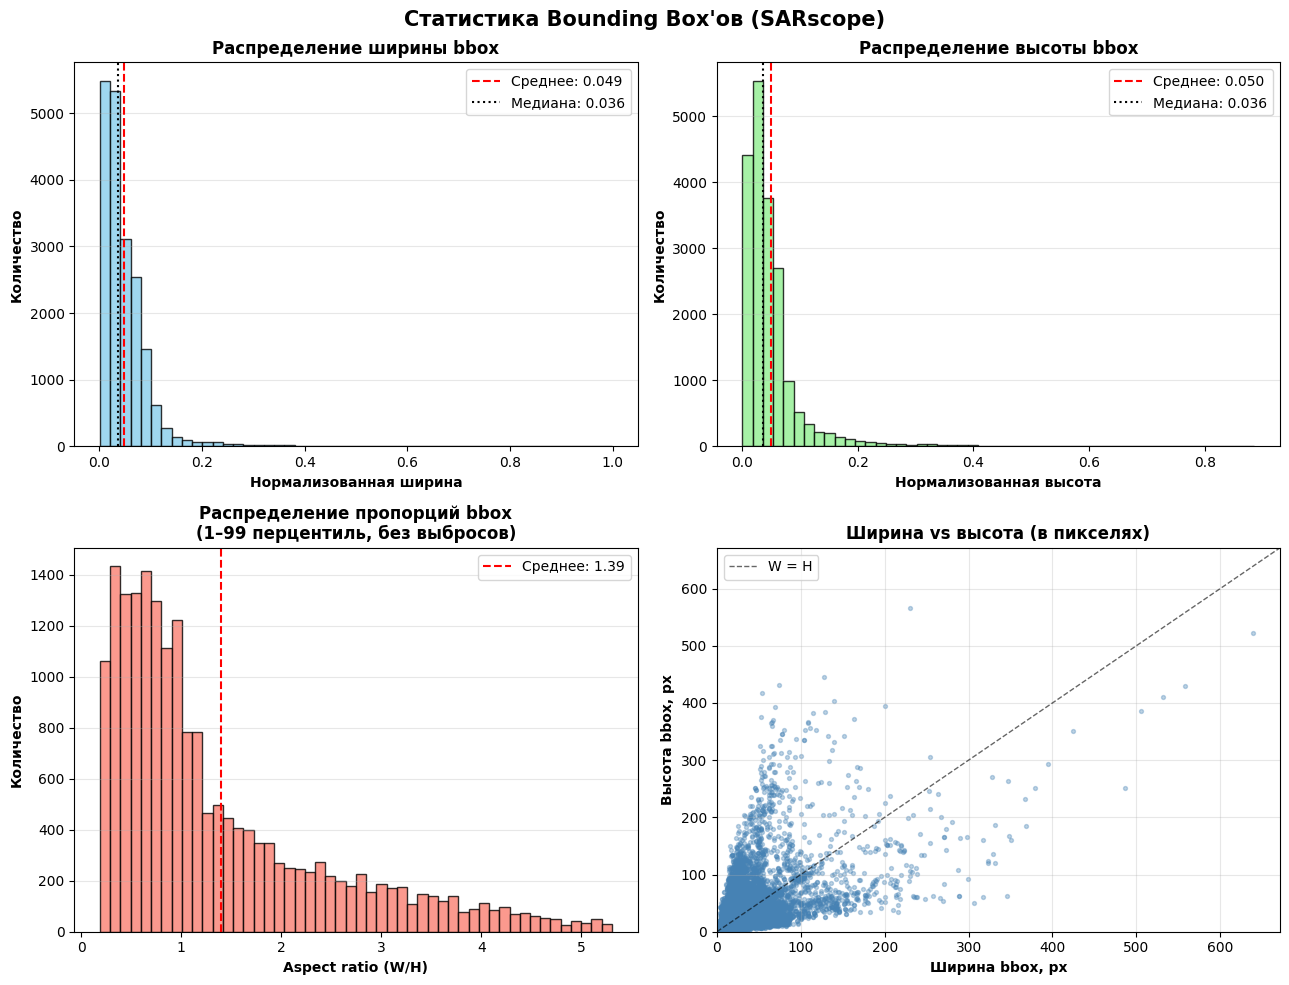

,Значение
Всего bbox,19435
Пропущено вырожденных (w<=0 или h<=0),0
Средняя ширина (норм.),0.049
Средняя высота (норм.),0.0501
Медианный aspect ratio (W/H),0.95
Мелкие объекты (<32x32px),13800 (71.0%)
Средние объекты (32-96px),5101 (26.2%)
Крупные объекты (>96x96px),534 (2.7%)


Вывод: 71% кораблей — мелкие объекты (<32×32 px при входе 640×640). После нескольких этапов pooling в backbone разрешение признаковой карты для таких объектов падает сильнее всего — ожидайте, что именно на них модель будет ошибаться чаще.


In [12]:
results = analyze_bbox_sizes(data_path)

## Конфигурация датасета и обучение модели

После подготовки датасета и конвертации форматов аннотаций, этот раздел настраивает YAML-файл для YOLOv8 и инициирует обучение модели.


### Создание пользовательского файла `dataset.yaml`

In [14]:
def infer_dataset_classes(base_path):
    """
    Определяет реальные классы по уже сконвертированным label-файлам (а не по
    предположению) и сопоставляет их человекочитаемым именам из исходного
    COCO json, если он ещё доступен. Несовпадение nc в dataset.yaml с
    реальными индексами в разметке -- частая причина падения обучения YOLO
    с ошибкой вида "Label class X exceeds nc=N" / CUDA device-side assert.
    """
    label_files = glob.glob(os.path.join(base_path, "*", "labels", "*.txt"))
    used_counts = {}
    for lf in label_files:
        with open(lf, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    cid = int(float(parts[0]))
                    used_counts[cid] = used_counts.get(cid, 0) + 1
    if not used_counts:
        raise RuntimeError("Не найдено ни одного размеченного класса в label-файлах -- "
                            "проверьте, что конвертация COCO -> YOLO выше прошла успешно.")
    nc = max(used_counts) + 1

    # Пробуем получить настоящие имена категорий из исходного COCO json
    id_to_name = {}
    for spl in ["train", "valid", "test"]:
        json_files = glob.glob(os.path.join(base_path, spl, "*.json"))
        for jf in json_files:
            try:
                with open(jf, "r", encoding="utf-8") as f:
                    coco = json.load(f)
                for cat in coco.get("categories", []):
                    id_to_name[cat["id"]] = cat["name"]
            except Exception:
                pass

    # Индекс класса в YOLO-файлах -- это исходный COCO category_id (pylabel не
    # переиндексирует категории). Поэтому имя ищем по тому же числовому id,
    # а не по позиции в списке: в SARscope ship имеет id=1, индекс 0 пустой.
    names = []
    for idx in range(nc):
        if idx in id_to_name:
            names.append(id_to_name[idx])
        elif idx in used_counts:
            names.append(f"class_{idx}")       # реально встречается, но имя не нашли
        else:
            names.append(f"unused_{idx}")      # индекс зарезервирован, реальных рамок нет

    counts_table = pd.Series(
        {f"{idx} ({names[idx]})": used_counts.get(idx, 0) for idx in range(nc)},
        name="Количество рамок"
    )
    print(f"Обнаружено классов: {nc}")
    display(counts_table.to_frame())
    print(f"Имена классов (dataset.yaml): {names}")

    return nc, names

In [15]:
# Удаляем возможный устаревший кэш разметки чтобы следующая попытка обучения гарантированно пересканировала данные заново, а не опиралась на кэш от прошлой конфигурации
cache_files = glob.glob(os.path.join(data_path, "*", "labels", "*.cache")) \
            + glob.glob(os.path.join(data_path, "*", "*.cache"))
for cf in cache_files:
    os.remove(cf)
    print(f"Удалён устаревший кэш: {cf}")
if not cache_files:
    print("Файлов кэша не найдено -- нечего удалять.")


nc, class_names = infer_dataset_classes(data_path)

train_dir = os.path.join(data_path, "train", "images")
val_dir = os.path.join(data_path, "valid", "images")
test_dir = os.path.join(data_path, "test", "images")

dataset_config = {
    "train": train_dir,
    "val": val_dir,
    "test": test_dir,
    "nc": nc,
    "names": class_names,
}

with open(os.path.join(data_path, "dataset.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump(dataset_config, f, allow_unicode=True, sort_keys=False)

Файлов кэша не найдено -- нечего удалять.
Обнаружено классов: 2


,Количество рамок
0 (unused_0),0
1 (ship),19435


Имена классов (dataset.yaml): ['unused_0', 'ship']


### Проверка файла конфигурации

Загружает и выводит содержимое `dataset.yaml` для подтверждения правильности перед началом обучения.

In [16]:
with open(os.path.join(data_path, "dataset.yaml"), "r") as f:
    file = yaml.safe_load(f)
print(file)

{'train': '<data_path>\\train\\images', 'val': '<data_path>\\valid\\images', 'test': '<data_path>\\test\\images', 'nc': 2, 'names': ['unused_0', 'ship']}


## Обучение

### Загрузка и обучение YOLOv8

- `YOLO(model="yolov8n.pt")` создаёт модель YOLOv8n и сразу загружает в неё веса, предобученные на датасете COCO (архитектура хранится внутри файла весов). При первом запуске файл скачивается автоматически.
- Старт с предобученных весов обычно ускоряет сходимость и улучшает качество, особенно при нехватке данных. Насколько это верно для SAR, проверим ниже в дополнительных экспериментах.
- Чтобы получить ту же архитектуру со случайными весами, используют файл конфигурации: `YOLO("yolov8n.yaml")`.

> YOLOv8n (nano) — самая лёгкая модель семейства, подходит там, где в приоритете вычислительная эффективность.

In [ ]:
model = YOLO(model="yolov8n.pt", task="detect")
model.info()

Команда ниже запускает процесс обучения со следующими параметрами:

- `data`: путь к файлу конфигурации датасета (пути к изображениям для обучения, валидации и теста, количество и имена классов).
- `epochs=50`: количество эпох обучения. Каждая эпоха проходит через весь обучающий датасет один раз.
- `imgsz=640`: размер входного изображения (640×640 — стандарт для YOLOv8 и совпадает с размером снимков SARscope).
- `device`: GPU `0`, если он доступен, иначе `"cpu"`.
- `seed=2026`: фиксируем сид для воспроизводимости, как и в блоке EDA.
- `name="train-pretrained"` и `exist_ok=True`: результаты сохраняются в `runs/detect/train-pretrained` (без `exist_ok` повторный запуск создал бы `train-pretrained2`, `train-pretrained3` и т.д.).

> Остальные параметры, в том числе все аугментации, оставляем по умолчанию. Полный список параметров — в [документации Ultralytics](https://docs.ultralytics.com/modes/train/#train-settings).

> **Нет GPU?** Пропустите ячейку обучения: ниже автоматически подхватятся готовые веса из папки `weights/` (`best_pretrained.pt`). Графики обучения в разделе «Метрики» при этом будут недоступны — они строятся по файлам запуска.

In [16]:
data = os.path.join(data_path, "dataset.yaml")
model.train(data=data,
            epochs=50,
            imgsz=640,
            device=0 if torch.cuda.is_available() else "cpu",
            seed=2026,
            name="train-pretrained",
            exist_ok=True)

Ultralytics 8.4.171  Python-3.12.3 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<data_path>\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-pretrained, nbs=64, nms=None, opset=None, o

##  Инференс и визуализация

Посмотрим на предсказания обученной модели на тестовых изображениях, чтобы визуально оценить качество.

Функция `find_run_dir` находит папку с результатами запуска по его имени — так ячейки ниже работают и без повторного обучения.

In [ ]:
WEIGHTS_DIR = "weights"  # готовые веса, обученные преподавателем

def find_run_dir(run_name, root="runs"):
    """Находит папку с результатами обучения по имени запуска (самую свежую, если их несколько).
    Возвращает None, если такого запуска нет (например, обучение пропущено)."""
    candidates = [p for p in glob.glob(os.path.join(root, "**", run_name), recursive=True) if os.path.isdir(p)]
    if not candidates:
        print(f"Запуск '{run_name}' не найден в '{root}' -- графики обучения для него будут пропущены")
        return None
    return max(candidates, key=os.path.getmtime)

def get_weights(run_name, fallback_file):
    """Веса своего запуска, если он есть, иначе -- готовые веса из WEIGHTS_DIR."""
    run_dir = find_run_dir(run_name)
    if run_dir is not None:
        return os.path.join(run_dir, "weights", "best.pt")
    return os.path.join(WEIGHTS_DIR, fallback_file)

results_dir = find_run_dir("train-pretrained")
best_weights = get_weights("train-pretrained", "best_pretrained.pt")
print("Используемые веса:", best_weights)

test_images_path = os.path.join(data_path, "test", "images")
test_images = sorted(glob.glob(os.path.join(test_images_path, "*.jpg")))

### Визуализация инференса на нескольких изображениях

In [18]:
model = YOLO(model=best_weights, task="detect")


0: 640x640 1 ship, 3.8ms
1: 640x640 2 ships, 3.8ms
2: 640x640 6 ships, 3.8ms
Speed: 41.3ms preprocess, 3.8ms inference, 11.3ms postprocess per image at shape (1, 3, 640, 640)


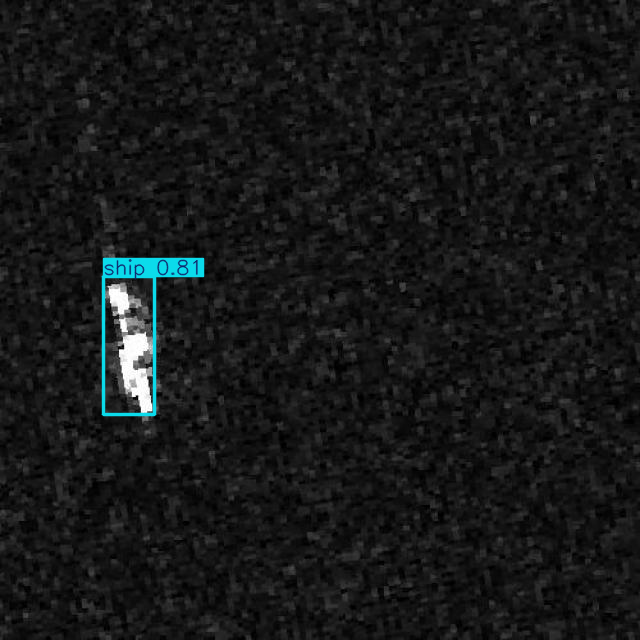

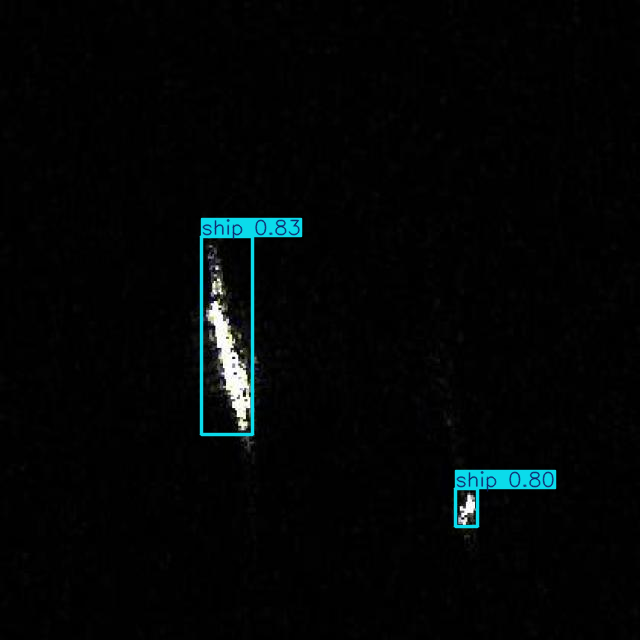

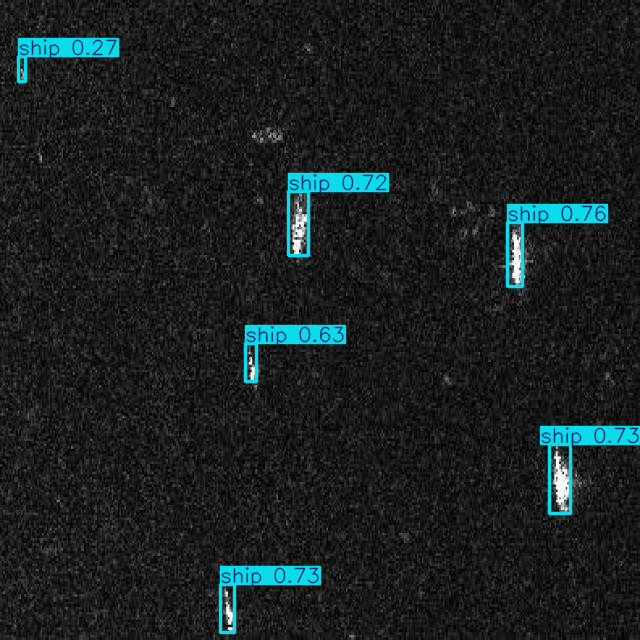

In [19]:
num_samples = 3
results = model(test_images[:num_samples], stream=False)
for i in range(num_samples):
    res = results[i].plot()
    display(Image.fromarray(res[..., ::-1]))  # plot() возвращает BGR, PIL ожидает RGB

## Метрики

Посмотрим на то, как обучалась модель, какими получились результаты и есть ли что улучшать.

> Все метрики в `results.csv` посчитаны на **валидационной** выборке после каждой эпохи. Файл `best.pt` — это веса эпохи с лучшей метрикой fitness (взвешенная комбинация mAP50 и mAP50-95), а не обязательно последней эпохи, поэтому значения «последней эпохи» ниже и метрики `best.pt` могут немного отличаться.

### Имеющиеся результаты

Для начала посмотрим на результаты, которые выдаёт сама модель

#### Результаты по метрикам

In [20]:
def plot_training_metrics(results_dir):
    # Загружаем результаты
    results = pd.read_csv(os.path.join(results_dir, "results.csv"))
    
    # Определяем доступные колонки
    print("Available metrics in results.csv:")
    print(results.columns.tolist())
    print("="*60)
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Epoch
    epochs = results['epoch'] if 'epoch' in results.columns else range(len(results))
    
    # 1. Losses
    if 'train/box_loss' in results.columns:
        axes[0, 0].plot(epochs, results['train/box_loss'], label='Train Box Loss', linewidth=2)
    if 'train/cls_loss' in results.columns:
        axes[0, 0].plot(epochs, results['train/cls_loss'], label='Train Class Loss', linewidth=2)
    if 'train/dfl_loss' in results.columns:
        axes[0, 0].plot(epochs, results['train/dfl_loss'], label='Train DFL Loss', linewidth=2)
    if 'val/box_loss' in results.columns:
        axes[0, 0].plot(epochs, results['val/box_loss'], label='Val Box Loss', linewidth=2)
    if 'val/cls_loss' in results.columns:
        axes[0, 0].plot(epochs, results['val/cls_loss'], label='Val Class Loss', linewidth=2)
    if 'val/dfl_loss' in results.columns:
        axes[0, 0].plot(epochs, results['val/dfl_loss'], label='Val DFL Loss', linewidth=2)
        
    axes[0, 0].set_xlabel('Epoch', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylabel('Loss', fontsize=11, fontweight='bold')
    axes[0, 0].set_title('Training Losses', fontsize=12, fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Precision & Recall
    if 'metrics/precision(B)' in results.columns:
        axes[0, 1].plot(epochs, results['metrics/precision(B)'], 
                       label='Precision', color='green', linewidth=2)
    if 'metrics/recall(B)' in results.columns:
        axes[0, 1].plot(epochs, results['metrics/recall(B)'], 
                       label='Recall', color='blue', linewidth=2)
    
    axes[0, 1].set_xlabel('Epoch', fontsize=11, fontweight='bold')
    axes[0, 1].set_ylabel('Score', fontsize=11, fontweight='bold')
    axes[0, 1].set_title('Precision & Recall', fontsize=12, fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].set_ylim([0, 1])
    
    # 3. mAP
    if 'metrics/mAP50(B)' in results.columns:
        axes[0, 2].plot(epochs, results['metrics/mAP50(B)'], 
                       label='mAP@50', color='purple', linewidth=2)
    if 'metrics/mAP50-95(B)' in results.columns:
        axes[0, 2].plot(epochs, results['metrics/mAP50-95(B)'], 
                       label='mAP@50-95', color='orange', linewidth=2)
    
    axes[0, 2].set_xlabel('Epoch', fontsize=11, fontweight='bold')
    axes[0, 2].set_ylabel('mAP', fontsize=11, fontweight='bold')
    axes[0, 2].set_title('Mean Average Precision', fontsize=12, fontweight='bold')
    axes[0, 2].legend()
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].set_ylim([0, 1])
    
    # 4. Learning Rate
    if 'lr/pg0' in results.columns:
        axes[1, 0].plot(epochs, results['lr/pg0'], label='PG0', linewidth=2)
    if 'lr/pg1' in results.columns:
        axes[1, 0].plot(epochs, results['lr/pg1'], label='PG1', linewidth=2)
    if 'lr/pg2' in results.columns:
        axes[1, 0].plot(epochs, results['lr/pg2'], label='PG2', linewidth=2)
    
    axes[1, 0].set_xlabel('Epoch', fontsize=11, fontweight='bold')
    axes[1, 0].set_ylabel('Learning Rate', fontsize=11, fontweight='bold')
    axes[1, 0].set_title('Learning Rate Schedule', fontsize=12, fontweight='bold')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # 5. Final metrics comparison (bar chart)
    if len(results) > 0:
        final_epoch = results.iloc[-1]
        metrics_names = ['metrics/precision(B)', 'metrics/recall(B)', 
                        'metrics/mAP50(B)', 'metrics/mAP50-95(B)']
        metrics_values = []
        metrics_labels = ['Precision', 'Recall', 'mAP@50', 'mAP@50-95']
        colors = ['green', 'blue', 'purple', 'orange']
        
        for metric in metrics_names:
            if metric in final_epoch:
                metrics_values.append(final_epoch[metric])
            else:
                metrics_values.append(0)
        
        axes[1, 1].bar(metrics_labels, metrics_values, color=colors, alpha=0.7, edgecolor='black')
        axes[1, 1].set_ylabel('Score', fontsize=11, fontweight='bold')
        axes[1, 1].set_title('Final Metrics (Last Epoch, val)', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylim([0, 1])
        
        # Подписываем значения
        for i, v in enumerate(metrics_values):
            axes[1, 1].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')
        
        axes[1, 1].grid(axis='y', alpha=0.3)
    
    # 6. Total loss
    if all(col in results.columns for col in ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']):
        total_loss = results['train/box_loss'] + results['train/cls_loss'] + results['train/dfl_loss']
        axes[1, 2].plot(epochs, total_loss, label='Total Train Loss', color='red', linewidth=2)
    if all(col in results.columns for col in ['val/box_loss', 'val/cls_loss', 'val/dfl_loss']):
        total_loss = results['val/box_loss'] + results['val/cls_loss'] + results['val/dfl_loss']
        axes[1, 2].plot(epochs, total_loss, label='Total Val Loss', color='lime', linewidth=2)
    axes[1, 2].set_xlabel('Epoch', fontsize=11, fontweight='bold')
    axes[1, 2].set_ylabel('Total Loss', fontsize=11, fontweight='bold')
    axes[1, 2].set_title('Total Loss', fontsize=12, fontweight='bold')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.suptitle('YOLOv8 Training Metrics Analysis', fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.show()
    
    # Вывод финальных метрик
    if len(results) > 0:
        print("\n" + "="*60)
        print("FINAL TRAINING METRICS (Last Epoch)")
        print("="*60)
        for col in results.columns:
            if col not in ['epoch']:
                print(f"{col:30s}: {results[col].iloc[-1]:.6f}")
        print("="*60)


Available metrics in results.csv:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


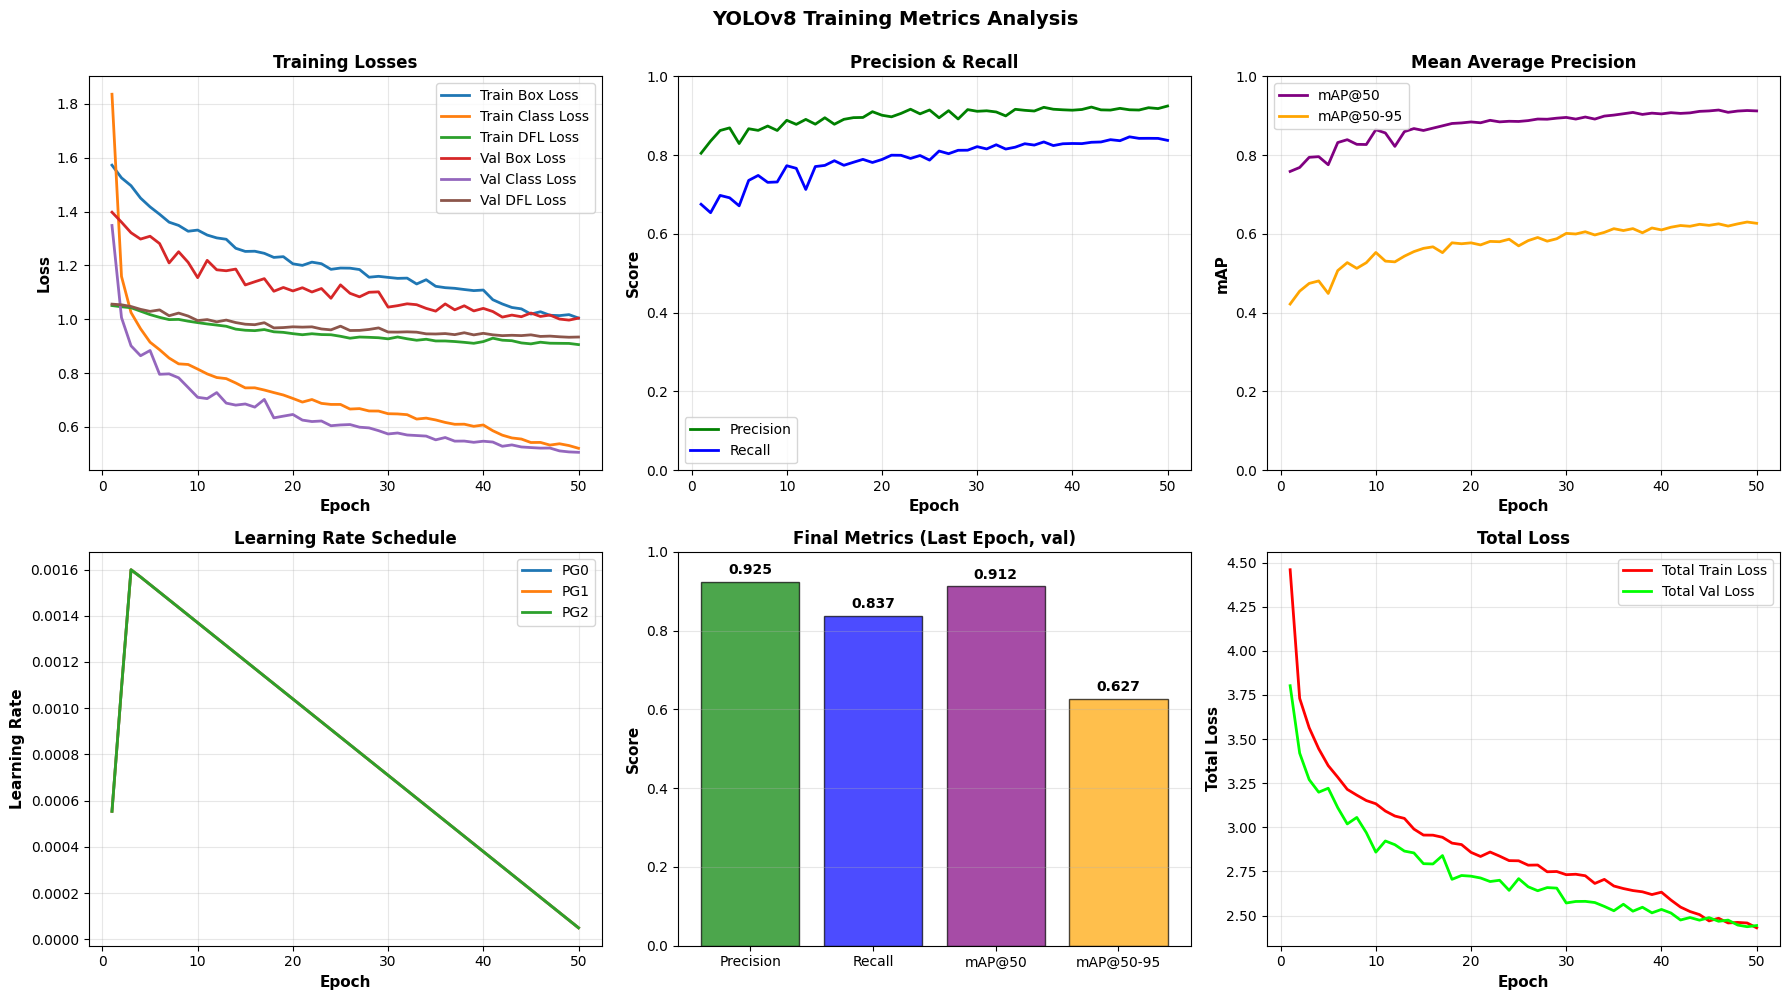


FINAL TRAINING METRICS (Last Epoch)
time                          : 1441.590000
train/box_loss                : 1.004470
train/cls_loss                : 0.520630
train/dfl_loss                : 0.905860
metrics/precision(B)          : 0.924660
metrics/recall(B)             : 0.837430
metrics/mAP50(B)              : 0.912220
metrics/mAP50-95(B)           : 0.626890
val/box_loss                  : 1.004140
val/cls_loss                  : 0.505680
val/dfl_loss                  : 0.934020
lr/pg0                        : 0.000050
lr/pg1                        : 0.000050
lr/pg2                        : 0.000050


In [21]:
if results_dir is not None:
    plot_training_metrics(results_dir)
else:
    print("Нет файлов своего запуска обучения -- пропускаем")

#### Визуализация кривых по метрикам

In [22]:
def visualize_validation_results(results_dir):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    # 1. PR Curve
    pr_curve_path = os.path.join(results_dir, 'BoxPR_curve.png')
    if os.path.exists(pr_curve_path):
        pr_img = Image.open(pr_curve_path)
        axes[0, 0].imshow(np.array(pr_img))
        axes[0, 0].axis('off')
        axes[0, 0].set_title('Precision-Recall Curve', fontsize=12, fontweight='bold')
    
    # 2. F1-Confidence Curve
    f1_curve_path = os.path.join(results_dir, 'BoxF1_curve.png')
    if os.path.exists(f1_curve_path):
        f1_img = Image.open(f1_curve_path)
        axes[0, 1].imshow(np.array(f1_img))
        axes[0, 1].axis('off')
        axes[0, 1].set_title('F1-Confidence Curve', fontsize=12, fontweight='bold')
    
    # 3. Precision-Confidence Curve
    prec_curve_path = os.path.join(results_dir, 'BoxP_curve.png')
    if os.path.exists(prec_curve_path):
        prec_img = Image.open(prec_curve_path)
        axes[1, 0].imshow(np.array(prec_img))
        axes[1, 0].axis('off')
        axes[1, 0].set_title('Precision-Confidence Curve', fontsize=12, fontweight='bold')
    
    # 4. Recall-Confidence Curve
    rec_curve_path = os.path.join(results_dir, 'BoxR_curve.png')
    if os.path.exists(rec_curve_path):
        rec_img = Image.open(rec_curve_path)
        axes[1, 1].imshow(np.array(rec_img))
        axes[1, 1].axis('off')
        axes[1, 1].set_title('Recall-Confidence Curve', fontsize=12, fontweight='bold')
    
    plt.suptitle('YOLOv8 Validation Metrics', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()


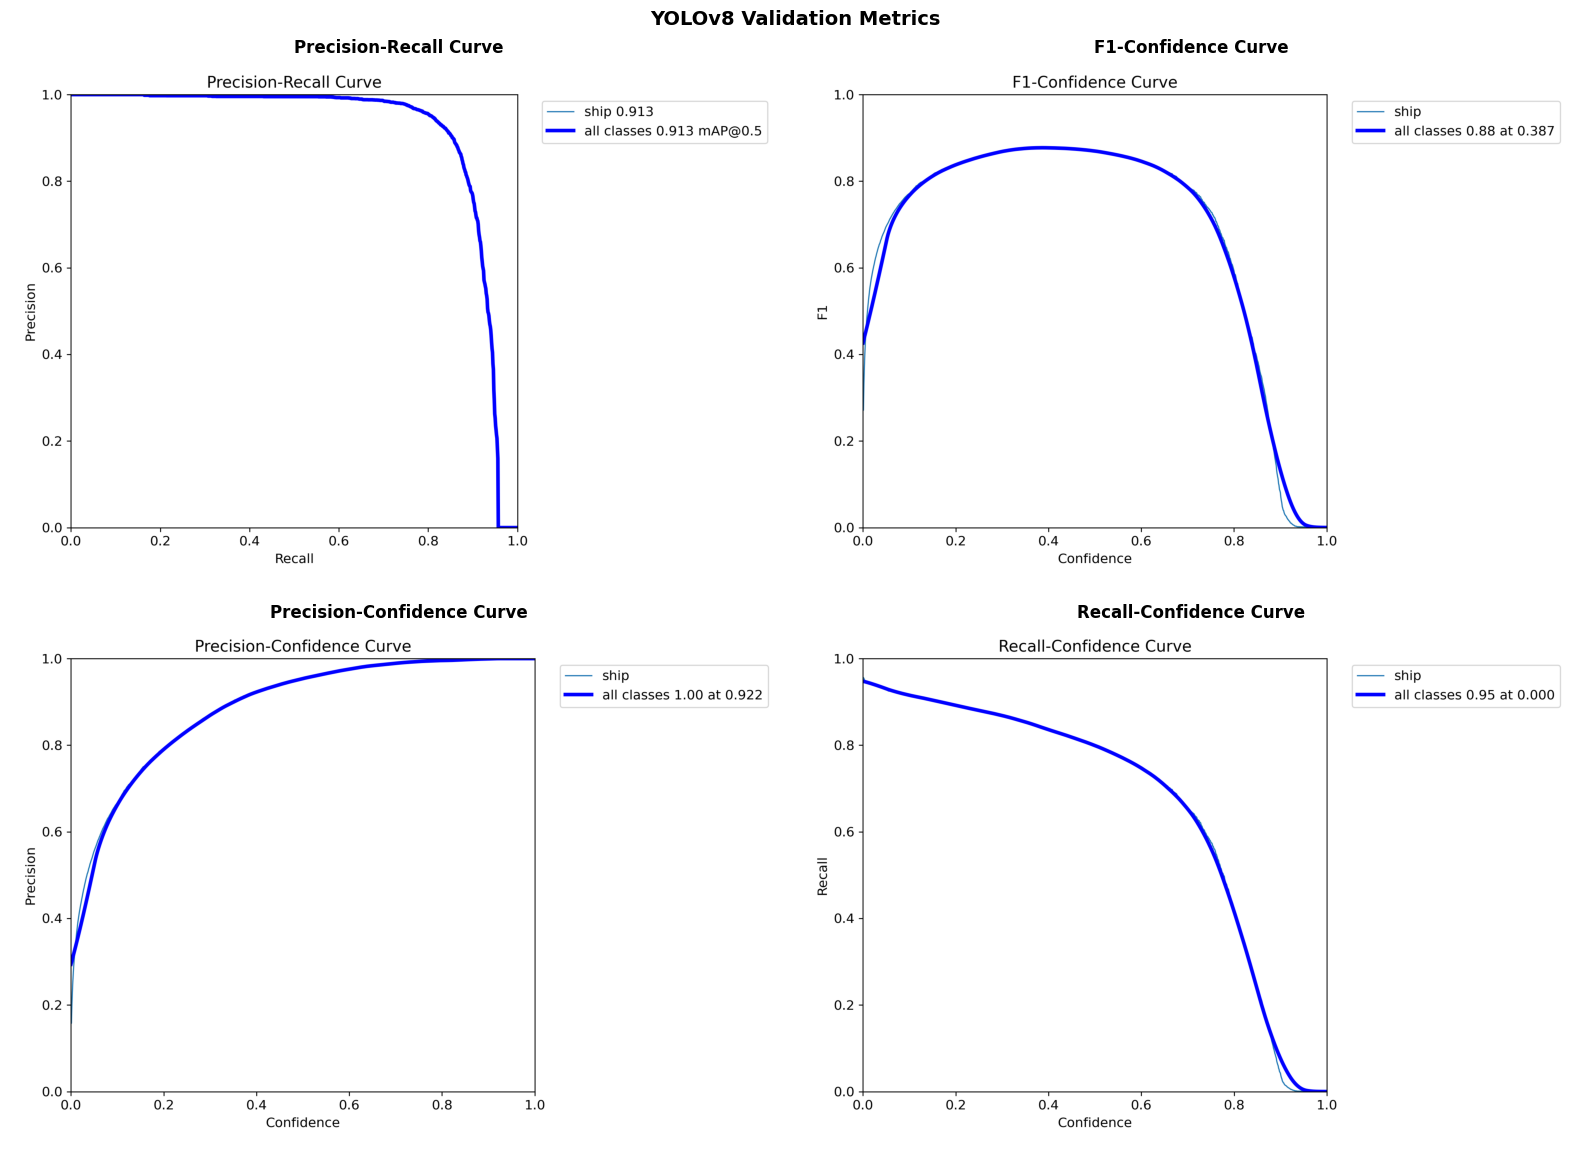

In [23]:
if results_dir is not None:
    visualize_validation_results(results_dir)
else:
    print("Нет файлов своего запуска обучения -- пропускаем")

#### Матрица ошибок

На первый взгляд матрица ниже выглядит странно: около 19 тыс. «кораблей», предсказанных на фоне, против 3,6 тыс. верных обнаружений — и это при mAP50 > 0.9. Противоречия здесь нет:

1. **Порог уверенности.** Матрица строится на финальной валидации после обучения, с тем же порогом, что и mAP: `conf=0.001`. В неё попадают все кандидаты, даже с уверенностью 0,1%, и почти все они — ложные срабатывания (FP). На mAP они почти не влияют: такие предсказания стоят в самом хвосте PR-кривой, где Recall уже ≈ 0.95. Это видно и по распределению уверенности ниже: медиана уверенности всех кандидатов меньше 0.01.
2. **Нет клетки «background → background».** В детекции нет истинно отрицательных (TN): фон не размечается и не считается, поэтому эта клетка всегда пустая.
3. **Строка и столбец `unused_0`** — пустой класс из-за нумерации категорий (см. раздел про конвертацию COCO → YOLO).

Вывод: матрицу ошибок детектора имеет смысл смотреть при **рабочем** пороге уверенности. Сразу после матрицы посчитаем TP / FP / FN на валидации при нескольких порогах.

In [24]:
def plot_confusion_matrix(results_dir):
    cm_path = os.path.join(results_dir, 'confusion_matrix.png')
    
    if os.path.exists(cm_path):
        cm_img = Image.open(cm_path)
        plt.figure(figsize=(10, 8))
        plt.imshow(np.array(cm_img))
        plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("Confusion matrix not found. Run validation first.")

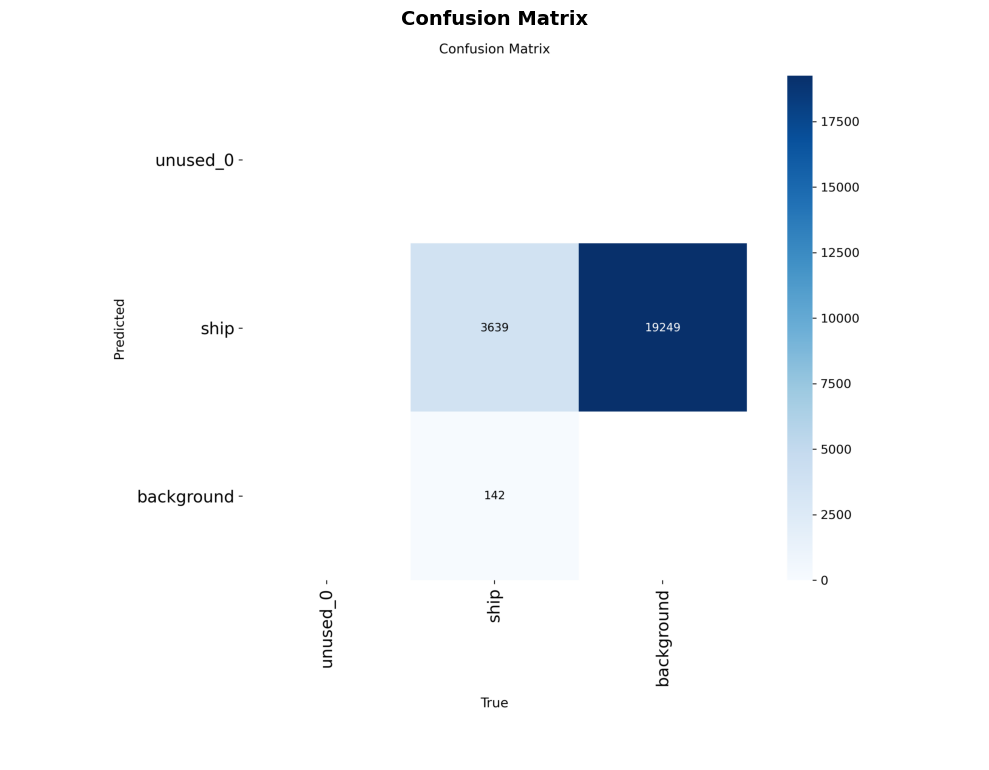

In [25]:
if results_dir is not None:
    plot_confusion_matrix(results_dir)
else:
    print("Нет файлов своего запуска обучения -- пропускаем")

Считаем TP / FP / FN сами: прогоняем модель по валидационной выборке один раз с `conf=0.001`, а затем отсекаем предсказания по разным порогам. Сопоставление с разметкой — жадное по убыванию уверенности, предсказание засчитывается как TP при IoU ≥ 0.5 (та же логика используется ниже в разделе с примерами предсказаний). Ultralytics сопоставляет рамки по своим правилам, поэтому при `conf=0.001` числа будут близки к матрице выше, но не обязаны совпасть точно.

Порог 0.39 взят с кривой F1-Confidence: на нём F1 максимален.

In [ ]:
def iou_matrix(a, b):
    """Матрица IoU между рамками a (N x 4) и b (M x 4) в формате xyxy."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def detection_counts_by_threshold(model, split="valid", thresholds=(0.001, 0.1, 0.25, 0.39, 0.5, 0.75), iou_thr=0.5):
    image_paths = sorted(glob.glob(os.path.join(data_path, split, "images", "*.jpg")))
    totals = {t: {"TP": 0, "FP": 0, "FN": 0} for t in thresholds}
    for res in model.predict(image_paths, conf=min(thresholds), stream=True, verbose=False):
        h, w = res.orig_shape
        label_path = os.path.join(os.path.dirname(os.path.dirname(res.path)), "labels",
                                  os.path.splitext(os.path.basename(res.path))[0] + ".txt")
        gt = []
        if os.path.exists(label_path):
            for line in open(label_path):
                parts = line.split()
                if len(parts) == 5:
                    _, xc, yc, bw, bh = map(float, parts)
                    gt.append([(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h])
        gt = np.array(gt).reshape(-1, 4)
        boxes = res.boxes.xyxy.cpu().numpy()
        confs = res.boxes.conf.cpu().numpy()
        order = np.argsort(-confs)
        boxes, confs = boxes[order], confs[order]
        ious = iou_matrix(boxes, gt)
        for t in thresholds:
            n_pred = int((confs >= t).sum())  # предсказания отсортированы по убыванию уверенности
            matched = set()
            tp = 0
            for p in range(n_pred):
                if len(gt) == 0:
                    break
                cand = [(ious[p, g], g) for g in range(len(gt)) if g not in matched]
                if cand:
                    best_iou, best_g = max(cand)
                    if best_iou >= iou_thr:
                        matched.add(best_g)
                        tp += 1
            totals[t]["TP"] += tp
            totals[t]["FP"] += n_pred - tp
            totals[t]["FN"] += len(gt) - tp

    table = pd.DataFrame(totals).T
    table.index.name = "Порог conf"
    table["Precision"] = (table["TP"] / (table["TP"] + table["FP"]).clip(lower=1)).round(3)
    table["Recall"] = (table["TP"] / (table["TP"] + table["FN"])).round(3)
    return table


counts = detection_counts_by_threshold(model)
display(counts)

### Валидация результатов на тестовой выборке

Теперь посчитаем метрики на тестовой выборке, которую модель не видела ни при обучении, ни при выборе `best.pt`.

Важно не перепутать два порога:
- `conf` — порог уверенности. Для подсчёта mAP он должен быть очень низким (по умолчанию `0.001`): mAP — площадь под PR-кривой, которая строится перебором порогов уверенности. Если поставить `conf=0.25`, все предсказания ниже 0.25 отбрасываются, PR-кривая обрывается, и mAP получается заниженным.
- `iou` — порог IoU для **NMS** (подавления пересекающихся рамок), по умолчанию `0.7`. Это **не** порог IoU для сопоставления с разметкой: в mAP50 рамка засчитывается при IoU ≥ 0.5 независимо от этого параметра.

Рабочий порог `conf` (например, 0.25) выбирают отдельно — под нужный баланс Precision/Recall, — и он нужен для инференса, а не для mAP.

In [26]:
data_yaml_path = os.path.join(data_path, "dataset.yaml")
metrics = model.val(
        data=data_yaml_path,
        split="test",
        batch=16,
        imgsz=640,
        conf=0.001,  # низкий порог уверенности -- обязательное условие корректного mAP
        iou=0.7,     # порог IoU для NMS (значение по умолчанию)
        plots=True,
    )
print(f"Test: mAP50 = {metrics.box.map50:.3f}, mAP50-95 = {metrics.box.map:.3f}")

Ultralytics 8.4.171  Python-3.12.3 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING val: Slow image access detected (ping: 0.00.0 ms, read: 4.11.5 MB/s, size: 89.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning <data_path>\test\labels... 672 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 672/672 283.3it/s 2.4s0.0s
val: New cache created: <data_path>\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 42/42 1.9it/s 22.0s0.2s
                   all        672       2014      0.921      0.828      0.904      0.608
                  ship        672       2014      0.921      0.828      0.904      0.608
Speed: 1.1ms preprocess, 3.2ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to runs\

In [27]:
def analyze_prediction_confidence(model, test_images_path, num_samples=100):
    test_images = glob.glob(os.path.join(test_images_path, "*.jpg"))
    selected_images = random.sample(test_images, min(num_samples, len(test_images)))
    
    all_confidences = []
    detections_per_image = []
    
    for img_path in selected_images:
        results = model(img_path, conf=0.001, verbose=False)  # Низкий порог для всех детекций
        if len(results) > 0 and results[0].boxes is not None:
            confs = results[0].boxes.conf.cpu().numpy()
            all_confidences.extend(confs)
            detections_per_image.append(len(confs))
        else:
            detections_per_image.append(0)
    
    # Визуализация
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # 1. Confidence distribution
    if all_confidences:
        axes[0].hist(all_confidences, bins=50, color='steelblue', 
                    edgecolor='black', alpha=0.7)
        axes[0].axvline(np.mean(all_confidences), color='red', linestyle='--', 
                       label=f'Mean: {np.mean(all_confidences):.3f}')
        axes[0].axvline(0.25, color='green', linestyle=':', 
                       label='Typical working threshold (0.25)')
        axes[0].set_xlabel('Confidence Score', fontsize=11, fontweight='bold')
        axes[0].set_ylabel('Count', fontsize=11, fontweight='bold')
        axes[0].set_title('Distribution of Prediction Confidence', 
                         fontsize=12, fontweight='bold')
        axes[0].legend()
        axes[0].grid(axis='y', alpha=0.3)
    
    # 2. Detections per image
    axes[1].hist(detections_per_image, bins=range(max(detections_per_image)+2), 
                color='coral', edgecolor='black', alpha=0.7)
    axes[1].axvline(np.mean(detections_per_image), color='red', linestyle='--', 
                   label=f'Mean: {np.mean(detections_per_image):.2f}')
    axes[1].set_xlabel('Number of Detections', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('Count', fontsize=11, fontweight='bold')
    axes[1].set_title('Detections per Image', fontsize=12, fontweight='bold')
    axes[1].legend()
    axes[1].grid(axis='y', alpha=0.3)
    
    plt.suptitle('Model Prediction Analysis', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Статистика
    print("="*60)
    print("PREDICTION CONFIDENCE ANALYSIS")
    print("="*60)
    print(f"Total detections: {len(all_confidences)}")
    print(f"Average confidence: {np.mean(all_confidences):.4f}")
    print(f"Median confidence: {np.median(all_confidences):.4f}")
    print(f"Std confidence: {np.std(all_confidences):.4f}")
    print(f"Min confidence: {min(all_confidences):.4f}")
    print(f"Max confidence: {max(all_confidences):.4f}")
    print(f"\nDetections above 0.25: {sum(1 for c in all_confidences if c >= 0.25)}")
    print(f"Detections above 0.5:  {sum(1 for c in all_confidences if c >= 0.5)}")
    print(f"Detections above 0.75: {sum(1 for c in all_confidences if c >= 0.75)}")
    print("="*60)

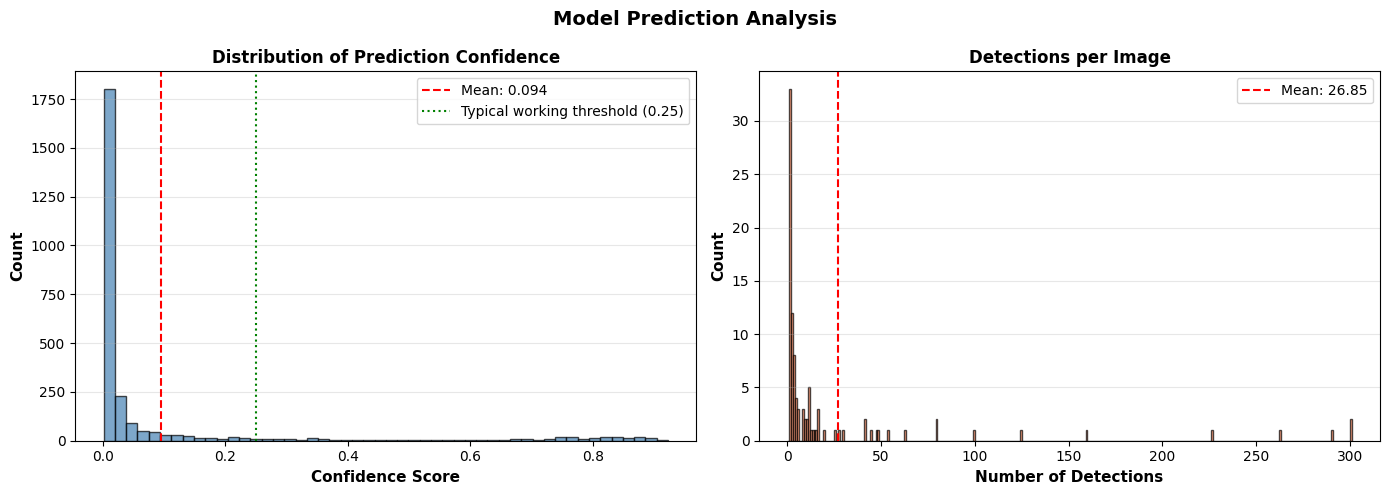

PREDICTION CONFIDENCE ANALYSIS
Total detections: 2685
Average confidence: 0.0939
Median confidence: 0.0066
Std confidence: 0.2158
Min confidence: 0.0010
Max confidence: 0.9228

Detections above 0.25: 309
Detections above 0.5:  221
Detections above 0.75: 142


In [28]:
analyze_prediction_confidence(model, test_images_path)

## Дополнительные эксперименты

Ниже три расширения базового пайплайна:
1. Обучение без спорных для SAR аугментаций.
2. Сравнение обучения с предобученных весов против обучения с нуля.
3. Подборка конкретных примеров предсказаний модели по категориям сложности.

Для сравнения запусков используем общую функцию `compare_training_runs`: она рисует кривые метрик двух запусков по эпохам, сравнивает финальные значения и показывает, на какой эпохе каждый запуск впервые достиг заданного mAP50.

> Без GPU обучение в этом разделе можно пропустить: готовые веса всех трёх моделей лежат в `weights/` (`best_pretrained.pt`, `best_safe_aug.pt`, `best_scratch.pt`) — их можно загрузить через `YOLO(...)` и сравнить на тесте через `model.val(...)`.

#### Вспомогательная функция: сравнение двух запусков

In [29]:
def compare_training_runs(results_dir_a, label_a, results_dir_b, label_b, map50_bar=0.5):
    """
    Сравнивает кривые обучения двух запусков (например, предобученные веса
    против обучения с нуля) по ключевым метрикам.
    """
    df_a = pd.read_csv(os.path.join(results_dir_a, "results.csv"))
    df_b = pd.read_csv(os.path.join(results_dir_b, "results.csv"))
    df_a.columns = [c.strip() for c in df_a.columns]
    df_b.columns = [c.strip() for c in df_b.columns]

    metrics = [
        ("metrics/precision(B)", "Precision"),
        ("metrics/recall(B)", "Recall"),
        ("metrics/mAP50(B)", "mAP@50"),
        ("metrics/mAP50-95(B)", "mAP@50-95"),
    ]

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    for ax, (col, title) in zip(axes, metrics):
        if col in df_a.columns:
            ax.plot(df_a["epoch"], df_a[col], label=label_a, color="steelblue", linewidth=2)
        if col in df_b.columns:
            ax.plot(df_b["epoch"], df_b[col], label=label_b, color="indianred", linewidth=2)
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.set_xlabel("Epoch"); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
        ax.legend()
    plt.suptitle(f"{label_a} vs {label_b}: кривые обучения", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

    final_a, final_b = df_a.iloc[-1], df_b.iloc[-1]
    summary = pd.DataFrame({
        label_a: [final_a.get(c, float("nan")) for c, _ in metrics],
        label_b: [final_b.get(c, float("nan")) for c, _ in metrics],
    }, index=[t for _, t in metrics])
    display(summary.round(4))

    fig2, ax2 = plt.subplots(figsize=(8, 5))
    x = np.arange(len(metrics))
    width = 0.35
    ax2.bar(x - width / 2, summary[label_a], width, label=label_a, color="steelblue")
    ax2.bar(x + width / 2, summary[label_b], width, label=label_b, color="indianred")
    ax2.set_xticks(x); ax2.set_xticklabels(summary.index)
    ax2.set_ylim(0, 1); ax2.legend(); ax2.grid(axis="y", alpha=0.3)
    ax2.set_title("Финальные метрики: сравнение", fontsize=13, fontweight="bold")
    for i, (va, vb) in enumerate(zip(summary[label_a], summary[label_b])):
        ax2.text(i - width / 2, va + 0.02, f"{va:.2f}", ha="center", fontsize=9)
        ax2.text(i + width / 2, vb + 0.02, f"{vb:.2f}", ha="center", fontsize=9)
    plt.tight_layout()
    plt.show()

    # Скорость сходимости: на какой эпохе mAP50 впервые превысил порог
    def first_epoch_above(df, col, bar):
        above = df.index[df[col] >= bar] if col in df.columns else []
        return int(df.loc[above[0], "epoch"]) if len(above) else None

    epoch_a = first_epoch_above(df_a, "metrics/mAP50(B)", map50_bar)
    epoch_b = first_epoch_above(df_b, "metrics/mAP50(B)", map50_bar)
    print(f"Эпоха первого достижения mAP@50 >= {map50_bar}: "
          f"{label_a} -- {epoch_a if epoch_a else 'не достигнуто'}, "
          f"{label_b} -- {epoch_b if epoch_b else 'не достигнуто'}")

    map_a = final_a.get("metrics/mAP50-95(B)", float("nan"))
    map_b = final_b.get("metrics/mAP50-95(B)", float("nan"))
    better = label_a if map_a > map_b else label_b
    print(f"Вывод: по финальному mAP@50-95 лучше показал себя запуск «{better}» "
          f"({max(map_a, map_b):.3f} против {min(map_a, map_b):.3f}).")

    return summary

### Обучение без спорных для SAR аугментаций

В лекции разбирали, что часть аугментаций рискованна именно для SAR: геометрические трансформации (повороты, отражения, сдвиги) безопасны, а операции, маскирующие часть изображения (CutOut-подобные) или искажающие цветовые каналы, могут быть физически некорректны или уничтожать полезный сигнал (например, кильватерный след корабля).

Посмотрим, что из этого реально включено в дефолтных настройках YOLOv8 для детекции:
- `hsv_h` / `hsv_s` — сдвиг тона и насыщенности. Снимки SARscope серые (три одинаковых канала), у серого пикселя насыщенность нулевая, поэтому на наших данных эти аугментации **фактически ничего не делают**.
- `hsv_v=0.4` — случайное изменение яркости. Это единственная из трёх, которая реально меняет изображение. В лекции умеренное изменение яркости отнесено к допустимым (имитирует разную калибровку и условия съёмки), но значение 0.4 довольно агрессивное — проверим, как оно влияет.
- `erasing=0.4` — Random Erasing. В Ultralytics он применяется **только при обучении классификаторов**, на детекцию не влияет; отключаем его для наглядности.
- `mosaic=1.0` остаётся включённым: мозаика склеивает четыре снимка в один кадр, но не накладывает их друг на друга, поэтому физически некорректных смесей сигналов не возникает.

Запускаем то же обучение (те же предобученные веса, эпохи и `seed`), отключив `hsv_*` и `erasing`. По сути, этот эксперимент проверяет влияние аугментации яркости.

In [21]:
model_safe_aug = YOLO(model="yolov8n.pt", task="detect")
model_safe_aug.train(data=os.path.join(data_path, "dataset.yaml"),
                      epochs=50,
                      imgsz=640,
                      device=0 if torch.cuda.is_available() else "cpu",
                      seed=2026,
                      name="train-pretrained-safeaug",
                      exist_ok=True,
                      erasing=0.0,
                      hsv_h=0.0,
                      hsv_s=0.0,
                      hsv_v=0.0)

Ultralytics 8.4.171  Python-3.12.3 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<data_path>\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.0, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-pretrained-safeaug, nbs=64, nms=None, opset=N

### Сравнение: дефолтные аугментации vs без аугментаций цвета и яркости

Сравниваем с основным обучением: та же инициализация весов (предобученные COCO-веса) и те же остальные параметры, различается только набор аугментаций.

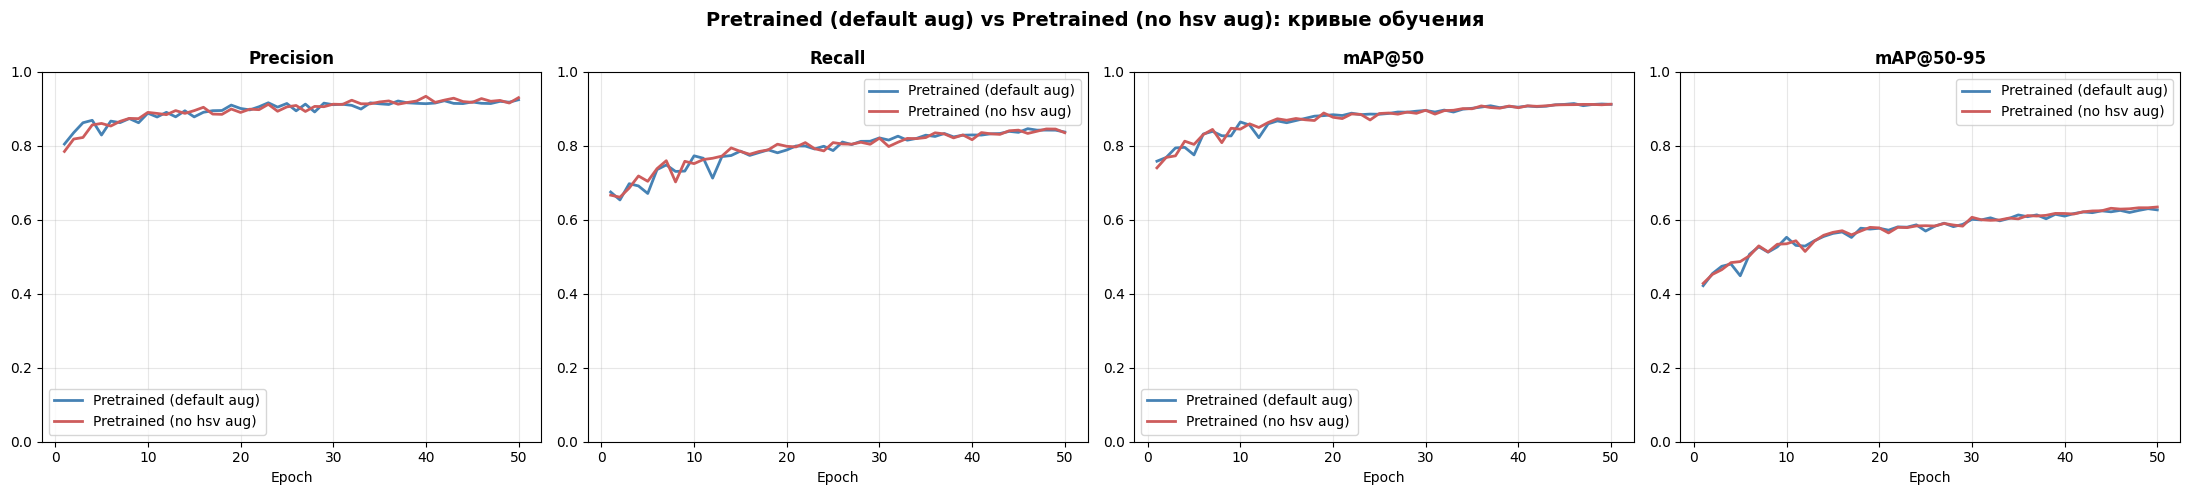

,Pretrained (default aug),Pretrained (no hsv aug)
Precision,0.9247,0.9303
Recall,0.8374,0.8355
mAP@50,0.9122,0.9126
mAP@50-95,0.6269,0.6347


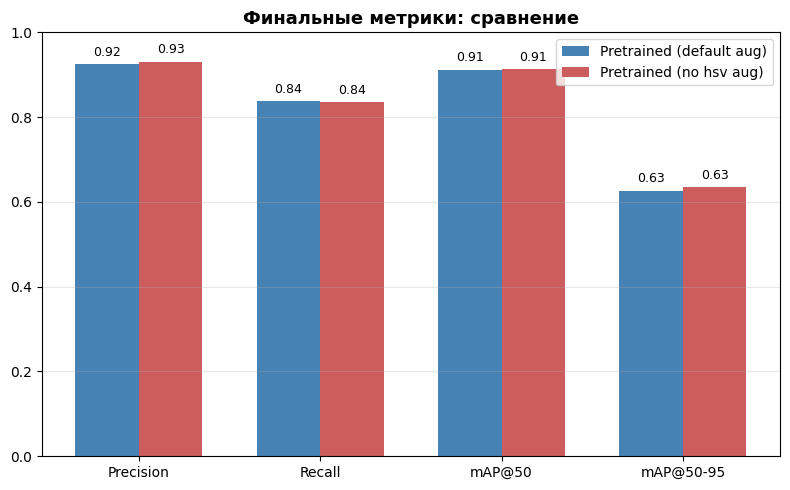

Эпоха первого достижения mAP@50 >= 0.8: Pretrained (default aug) -- 6, Pretrained (no hsv aug) -- 4
Вывод: по финальному mAP@50-95 лучше показал себя запуск «Pretrained (no hsv aug)» (0.635 против 0.627).


In [31]:
results_dir_safe_aug = find_run_dir("train-pretrained-safeaug")
if results_dir is not None and results_dir_safe_aug is not None:
    summary_safe_aug = compare_training_runs(results_dir, "Pretrained (default aug)",
                                             results_dir_safe_aug, "Pretrained (no hsv aug)",
                                             map50_bar=0.8)

### Зачем сравнивать обучение с нуля и с предобученных весов

- Модель `model` выше инициализирована весами, предобученными на COCO — обычных оптических фотографиях. SAR-изображения сильно отличаются от COCO (см. лекцию: нет цвета и привычной текстуры, спекл-шум, другая природа яркости пикселя), поэтому заранее не очевидно, насколько полезен перенос обучения (*transfer learning*) с настолько другого домена.
- Обучение с нуля (случайная инициализация весов, та же архитектура YOLOv8n) — честный бейзлайн, который покажет, даёт ли предобучение на COCO реальное преимущество именно для SAR.
- Сравниваем при одинаковых условиях: та же архитектура, тот же датасет, то же число эпох (`50`), тот же `seed`.

> В логе обучения ниже будет `pretrained=True` — это не значит, что веса загрузились: для модели из `.yaml` этот флаг игнорируется, веса случайные.

In [40]:
model_scratch = YOLO("yolov8n.yaml")  # архитектура YOLOv8n БЕЗ предобученных весов
model_scratch.train(data=os.path.join(data_path, "dataset.yaml"),
                     epochs=50,
                     imgsz=640,
                     device=0 if torch.cuda.is_available() else "cpu",
                     seed=2026,
                     name="train-scratch",
                     exist_ok=True)

Ultralytics 8.4.171  Python-3.12.3 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 16380MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=<data_path>\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-scratch, nbs=64, nms=None, opset=None, op

### Сравнение кривых обучения

Сравниваем оба запуска по тем же метрикам, что уже видели в разделе «Метрики»: precision, recall, mAP@50, mAP@50-95 — по эпохам и в последней эпохе. Дополнительно смотрим, какой из запусков быстрее достиг разумного качества.

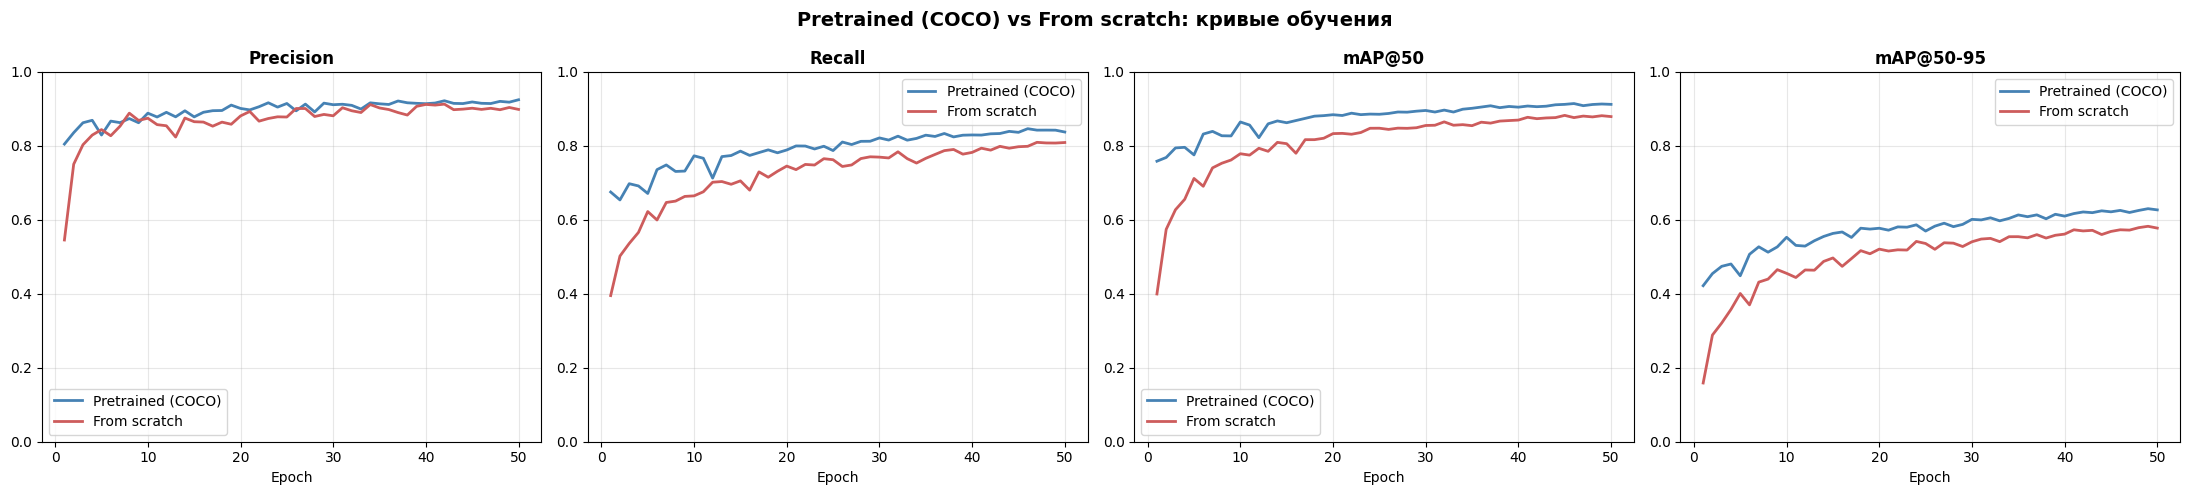

,Pretrained (COCO),From scratch
Precision,0.9247,0.8986
Recall,0.8374,0.8091
mAP@50,0.9122,0.8792
mAP@50-95,0.6269,0.5776


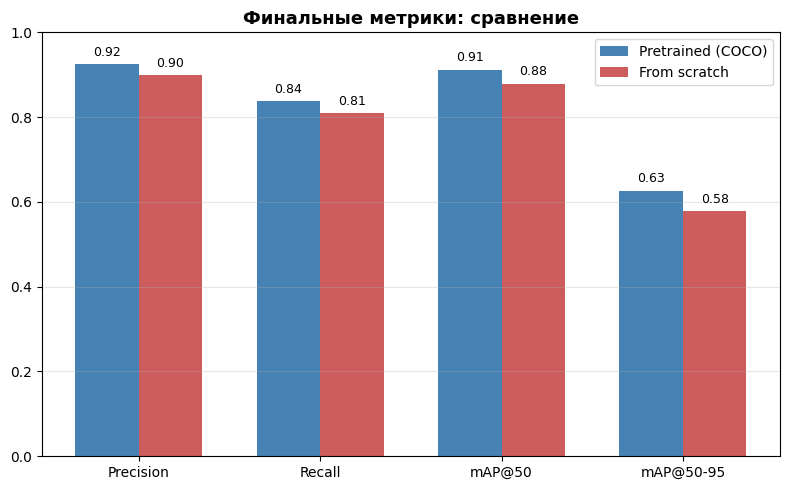

Эпоха первого достижения mAP@50 >= 0.8: Pretrained (COCO) -- 6, From scratch -- 14
Вывод: по финальному mAP@50-95 лучше показал себя запуск «Pretrained (COCO)» (0.627 против 0.578).


In [32]:
results_dir_scratch = find_run_dir("train-scratch")
if results_dir is not None and results_dir_scratch is not None:
    summary_scratch = compare_training_runs(results_dir, "Pretrained (COCO)", results_dir_scratch,
                                            "From scratch", map50_bar=0.8)

### Примеры предсказаний по категориям сложности

Хотим увидеть не просто "модель работает", а конкретные показательные случаи:
уверенное распознавание одиночной цели, корректную работу на кадре с кучей
кораблей сразу, и, что не менее важно, характерные ошибки отдельно для простых
(мало объектов) и сложных (много объектов) сцен.

Сопоставление предсказаний с разметкой делаем по той же логике IoU, что
разбирали в лекции: 
- предсказание засчитывается как верное (True Positive), если его IoU с какой-то размеченной рамкой корабля выше порога;  
- размеченные рамки без пары - пропущенные корабли (False Negative);  
- предсказания без пары - ложные срабатывания (False Positive).
  
Изображение считаем обработанным **корректно**, если на нём нет ни пропусков, ни ложных срабатываний.

In [33]:
def iou_xyxy(box_a, box_b):
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def match_predictions(gt_boxes, pred_boxes, pred_confs, iou_threshold=0.5):
    """Жадное сопоставление предсказаний с ground truth по убыванию confidence."""
    order = np.argsort(-np.array(pred_confs)) if len(pred_confs) else np.array([], dtype=int)
    matched_gt = set()
    tp, fp = 0, 0
    for idx in order:
        pbox = pred_boxes[idx]
        best_iou, best_j = 0.0, -1
        for j, gbox in enumerate(gt_boxes):
            if j in matched_gt:
                continue
            i = iou_xyxy(pbox, gbox)
            if i > best_iou:
                best_iou, best_j = i, j
        if best_iou >= iou_threshold and best_j >= 0:
            matched_gt.add(best_j)
            tp += 1
        else:
            fp += 1
    fn = len(gt_boxes) - len(matched_gt)
    return tp, fp, fn


def load_gt_boxes(label_path, img_size=640):
    boxes = []
    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    _, xc, yc, w, h = map(float, parts)
                    x1 = (xc - w / 2) * img_size
                    y1 = (yc - h / 2) * img_size
                    x2 = (xc + w / 2) * img_size
                    y2 = (yc + h / 2) * img_size
                    boxes.append((x1, y1, x2, y2))
    return boxes


def find_examples_by_criteria(model, images_dir, labels_dir, img_size=640,
                               iou_threshold=0.5, conf_threshold=0.25):
    """
    Прогоняет модель по всем изображениям в images_dir и раскладывает их по
    4 категориям: уверенно правильно (1 корабль / 5-10 кораблей) и с ошибкой
    (<=5 кораблей / >5 кораблей).
    """
    buckets = {"single_correct": [], "multi_correct": [], "few_error": [], "many_error": []}
    image_paths = sorted(glob.glob(os.path.join(images_dir, "*.jpg")))

    for img_path in image_paths:
        name = os.path.basename(img_path)
        label_path = os.path.join(labels_dir, name.replace(".jpg", ".txt"))
        gt_boxes = load_gt_boxes(label_path, img_size)
        n_gt = len(gt_boxes)
        if n_gt == 0:
            continue

        results = model(img_path, conf=conf_threshold, verbose=False)
        boxes = results[0].boxes
        pred_xyxy = boxes.xyxy.cpu().numpy() if boxes is not None else np.zeros((0, 4))
        pred_conf = boxes.conf.cpu().numpy() if boxes is not None else np.zeros((0,))

        tp, fp, fn = match_predictions(gt_boxes, list(pred_xyxy), list(pred_conf), iou_threshold)
        is_correct = (fp == 0 and fn == 0)

        record = {"path": img_path, "n_gt": n_gt, "tp": tp, "fp": fp, "fn": fn,
                  "pred_xyxy": pred_xyxy, "gt_xyxy": gt_boxes}

        if n_gt == 1 and is_correct:
            buckets["single_correct"].append(record)
        elif 5 <= n_gt <= 10 and is_correct:
            buckets["multi_correct"].append(record)
        elif n_gt <= 5 and not is_correct:
            buckets["few_error"].append(record)
        elif n_gt > 5 and not is_correct:
            buckets["many_error"].append(record)

    return buckets

In [34]:
test_images_path = os.path.join(data_path, "test", "images")
test_labels_path = os.path.join(data_path, "test", "labels")

example_buckets = find_examples_by_criteria(model, test_images_path, test_labels_path)

summary = pd.Series({
    "1 корабль, распознано верно": len(example_buckets["single_correct"]),
    "5-10 кораблей, распознано верно": len(example_buckets["multi_correct"]),
    "Ошибка, <=5 кораблей на кадре": len(example_buckets["few_error"]),
    "Ошибка, >5 кораблей на кадре": len(example_buckets["many_error"]),
}, name="Число изображений")
display(summary.to_frame())

,Число изображений
"1 корабль, распознано верно",309
"5-10 кораблей, распознано верно",22
"Ошибка, <=5 кораблей на кадре",104
"Ошибка, >5 кораблей на кадре",64


In [35]:
def plot_detection_example(record, title):
    img = Image.open(record["path"])
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(img)
    for k, (x1, y1, x2, y2) in enumerate(record["gt_xyxy"]):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                                        edgecolor="lime", facecolor="none",
                                        label="Ground Truth" if k == 0 else None))
    for k, (x1, y1, x2, y2) in enumerate(record["pred_xyxy"]):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                                        edgecolor="red", facecolor="none", linestyle="--",
                                        label="Predicted" if k == 0 else None))
    ax.set_title(f"{title}\nGT={record['n_gt']}  TP={record['tp']}  FP={record['fp']}  FN={record['fn']}",
                 fontsize=12, fontweight="bold")
    ax.legend(loc="upper right")
    ax.axis("off")
    plt.tight_layout()
    plt.show()

Категория «Корректно: 1 корабль»: найдено 309 подходящих изображений в тестовой выборке


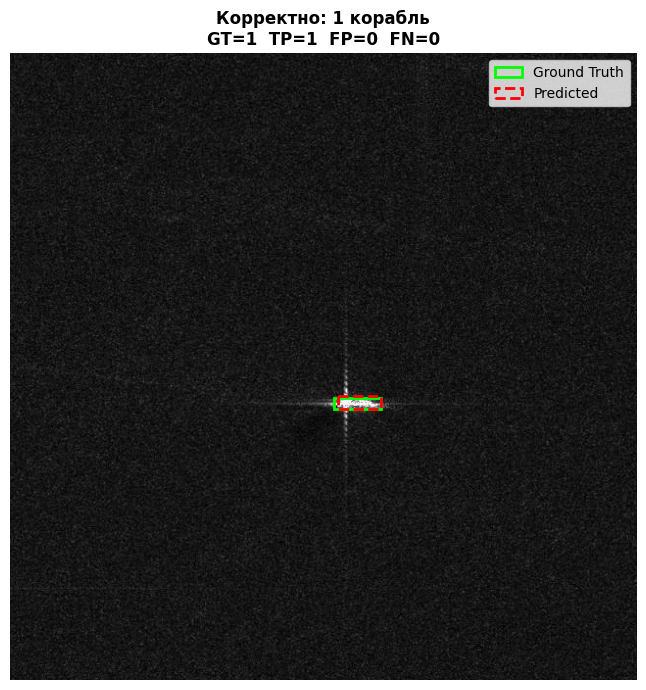


Категория «Корректно: 5-10 кораблей»: найдено 22 подходящих изображений в тестовой выборке


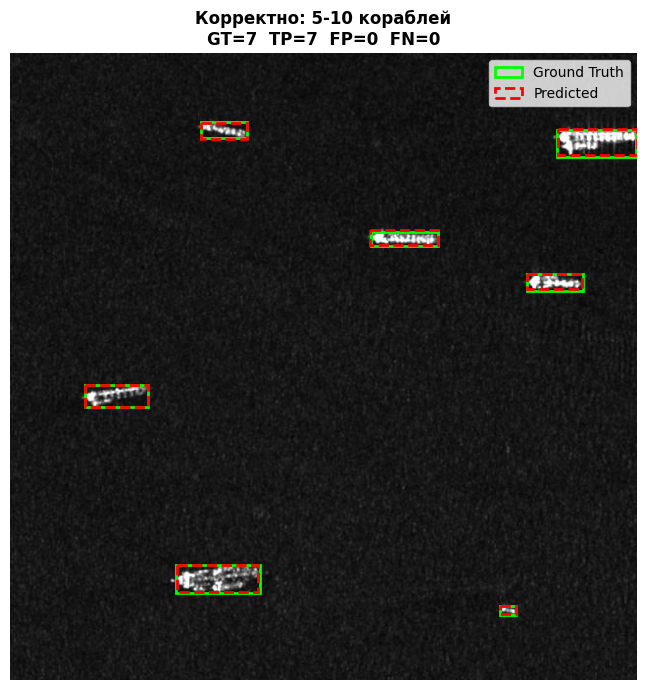


Категория «Ошибка: <=5 кораблей на кадре»: найдено 104 подходящих изображений в тестовой выборке


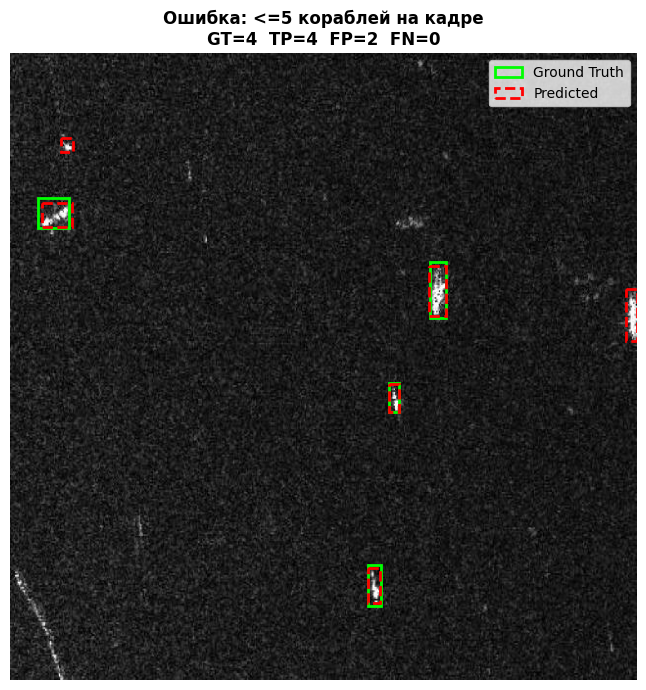


Категория «Ошибка: >5 кораблей на кадре»: найдено 64 подходящих изображений в тестовой выборке


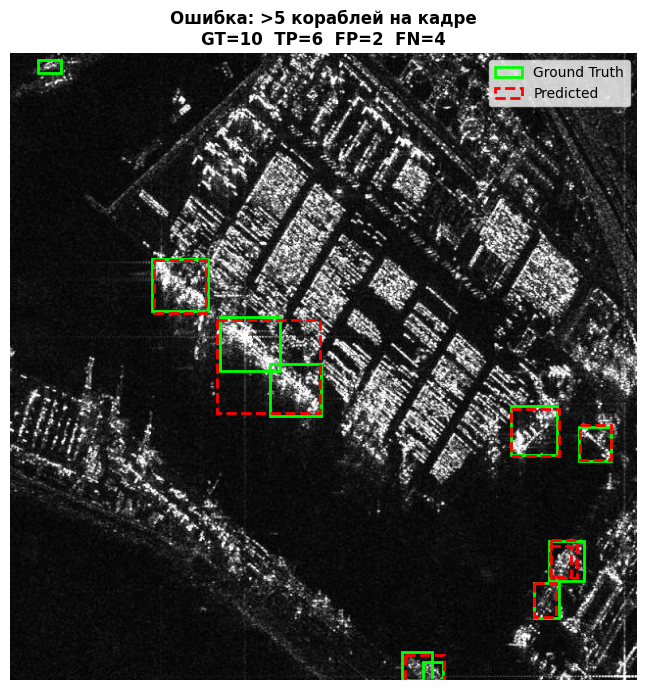

In [36]:
categories = [
    ("single_correct", "Корректно: 1 корабль"),
    ("multi_correct", "Корректно: 5-10 кораблей"),
    ("few_error", "Ошибка: <=5 кораблей на кадре"),
    ("many_error", "Ошибка: >5 кораблей на кадре"),
]

for key, title in categories:
    records = example_buckets[key]
    print(f"Категория «{title}»: найдено {len(records)} подходящих изображений в тестовой выборке")
    if records:
        example = random.choice(records)
        plot_detection_example(example, title)
    else:
        print("  Не найдено ни одного подходящего примера -- попробуйте снизить/повысить "
              "conf_threshold в find_examples_by_criteria, или такой случай просто "
              "отсутствует в тестовой выборке.")
    print()